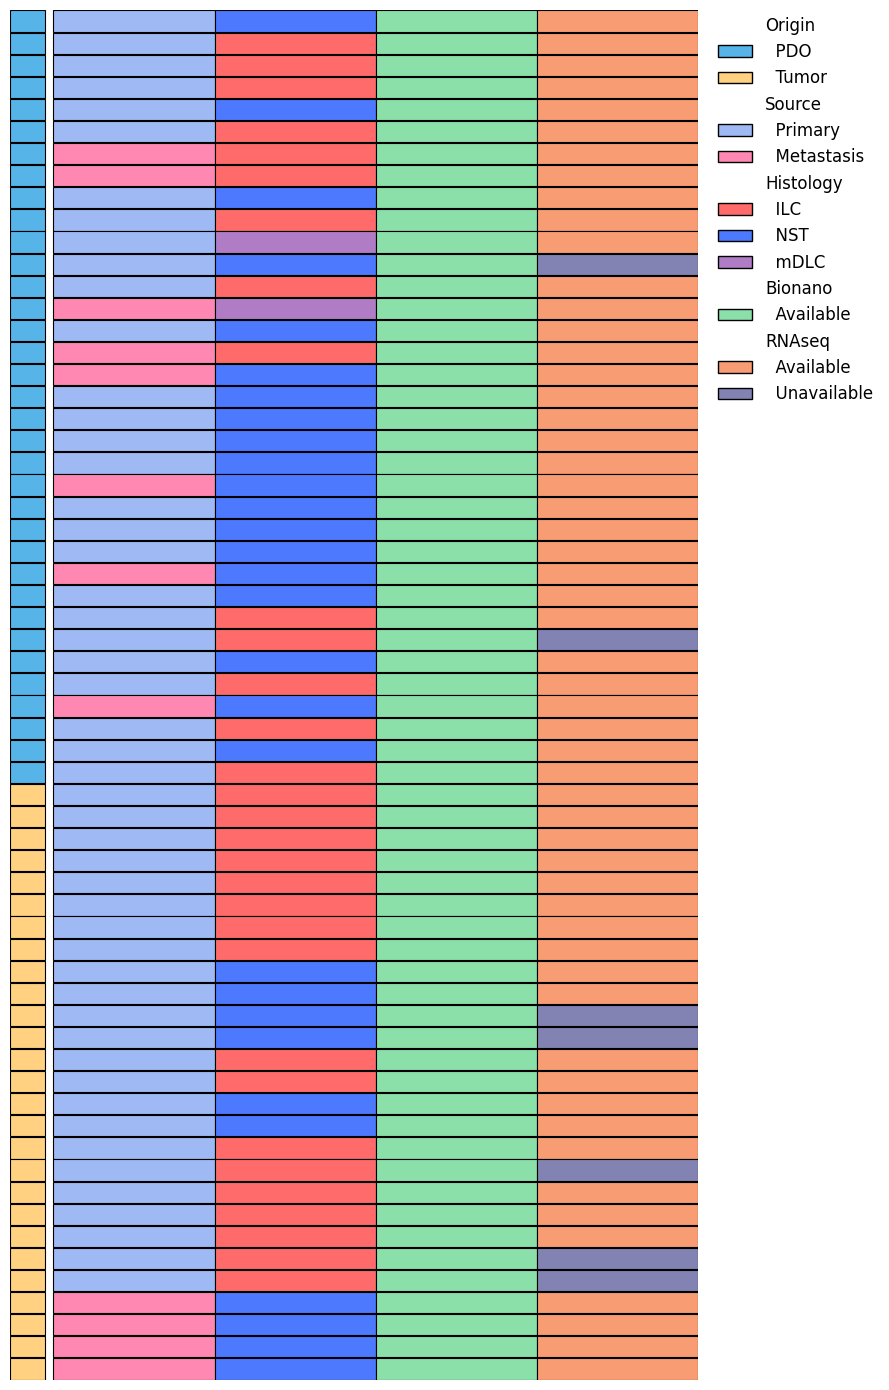

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# --- Load data ---
csv_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/Clinical/Bionano_cohort.csv"
df = pd.read_csv(csv_path)

# --- Clean whitespace only in string/object columns ---
for col in df.columns:
    if df[col].dtype == "object":
        df[col] = df[col].astype(str).str.strip()
        df[col] = df[col].replace({"nan": pd.NA, "": pd.NA})

# --- Define columns to visualize ---
columns_to_encode = ["Source", "Histology", "Bionano", "RNAseq"]
annotation_col = "Origin"

# --- Keep only expected category values; everything else becomes missing ---
allowed_values = {
    "Source": ["Primary", "Metastasis"],
    "Histology": ["ILC", "NST", "mDLC"],
    "Bionano": ["Yes"],
    "RNAseq": ["Yes", "No"],
    "Origin": ["PDO", "Tumor"]
}

for col, valid in allowed_values.items():
    df[col] = df[col].where(df[col].isin(valid), pd.NA)

# --- Color palettes ---
palette_map = {
    "Source": {
        "Primary": "#9EB9F3",
        "Metastasis": "#FE88B1"
    },
    "Histology": {
        "ILC": "#FF6B6B",
        "NST": "#4D79FF",
        "mDLC": "#B07CC6"
    },
    "Bionano": {
        "Yes": "#8BE0AA"
    },
    "RNAseq": {
        "Yes": "#F89C74",
        "No": "#8383B3"
    }
}

origin_color_map = {
    "PDO": "#56B4E9",
    "Tumor": "#FFD180"
}

# fallback color for missing/unexpected values
missing_color = "#E6E6E6"

# --- Build color matrix directly from category values ---
color_matrix = df.set_index("SampleID")[columns_to_encode].copy()
for col in columns_to_encode:
    color_matrix[col] = color_matrix[col].map(palette_map[col]).fillna(missing_color)

# --- Origin color ---
df["Origin_color"] = df[annotation_col].map(origin_color_map).fillna(missing_color)

# --- Plot settings ---
origin_strip_width = 0.22
row_spacing = 0.04
bar_height = 1 - row_spacing

fig, ax = plt.subplots(figsize=(9, 14))

# --- Plot Origin strip ---
for y, sample in enumerate(color_matrix.index):
    y_base = y + row_spacing / 2
    color = df.loc[df["SampleID"] == sample, "Origin_color"].iloc[0]
    ax.add_patch(plt.Rectangle(
        (-origin_strip_width - 0.05, y_base),
        origin_strip_width, bar_height,
        facecolor=color, edgecolor="black", linewidth=0.8
    ))

# --- Plot heatmap blocks ---
for y, sample in enumerate(color_matrix.index):
    y_base = y + row_spacing / 2
    for x, col in enumerate(color_matrix.columns):
        ax.add_patch(plt.Rectangle(
            (x, y_base), 1, bar_height,
            facecolor=color_matrix.loc[sample, col],
            edgecolor="black", linewidth=0.8
        ))

# --- Axes cleanup ---
ax.set_xlim(-origin_strip_width - 0.05, len(color_matrix.columns))
ax.set_ylim(0, len(color_matrix))
ax.set_xticks([])
ax.set_yticks([])
ax.invert_yaxis()
for spine in ax.spines.values():
    spine.set_visible(False)

# --- Build legend ---
legend_elements = []

legend_structure = {
    "Origin": ["PDO", "Tumor"],
    "Source": ["Primary", "Metastasis"],
    "Histology": ["ILC", "NST", "mDLC"],
    "Bionano": ["Yes"],
    "RNAseq": ["Yes", "No"]
}

label_alias = {
    "Yes": "Available",
    "No": "Unavailable"
}

legend_order = ["Origin", "Source", "Histology", "Bionano", "RNAseq"]

for col in legend_order:
    legend_elements.append(Patch(facecolor="white", edgecolor="white", label=col))

    if col == "Origin":
        for val in legend_structure[col]:
            legend_elements.append(
                Patch(facecolor=origin_color_map[val], edgecolor="black", label=f"  {val}")
            )
    else:
        for val in legend_structure[col]:
            legend_elements.append(
                Patch(
                    facecolor=palette_map[col][val],
                    edgecolor="black",
                    label=f"  {label_alias.get(val, val)}"
                )
            )

plt.legend(
    handles=legend_elements,
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=12,
    borderaxespad=0.0,
    frameon=False
)

plt.tight_layout()
plt.savefig(
    "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/Clinical/Cohort_Overview_Heatmap.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


PDO subtype counts:
HR+ Her2-        25
HR+ Her2+         4
HR- Her2-         1
HR- Her2+         4
HR+ Her2 Equi     1
dtype: int64

Tumor subtype counts:
HR+ Her2-        21
HR+ Her2+         3
HR- Her2-         2
HR+ Her2 Equi     1
dtype: int64


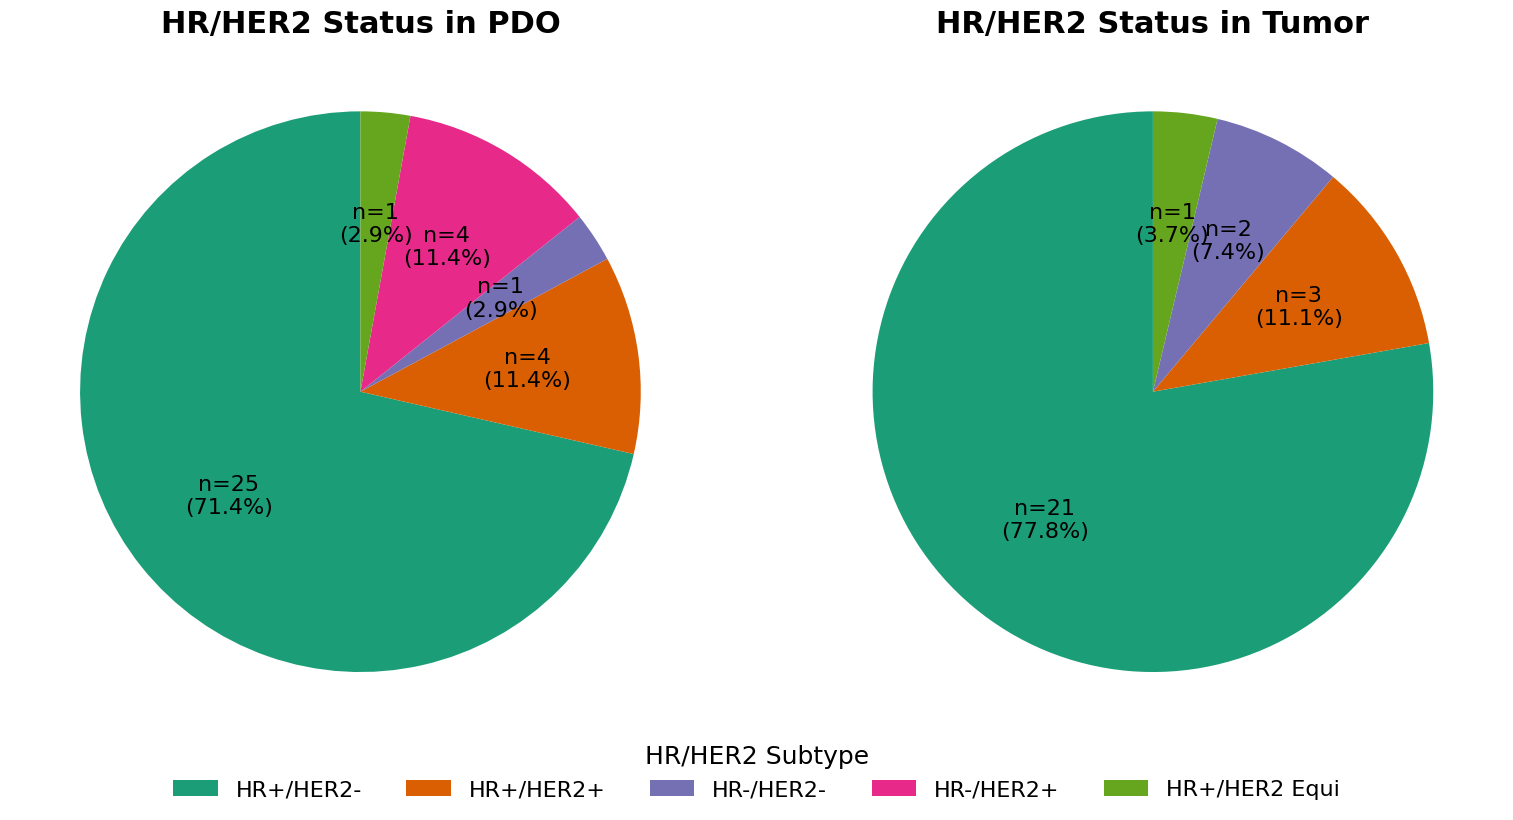


Saved files:
/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/Clinical/HR_HER2_subtype_pie.png
/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/Clinical/HR_HER2_subtype_pie.pdf


In [9]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# -----------------------------
# Load data
# -----------------------------
csv_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/Clinical/Bionano_cohort.csv"
df = pd.read_csv(csv_path)

# Clean whitespace
for col in df.columns:
    if df[col].dtype == "object":
        df[col] = df[col].astype(str).str.strip()

# -----------------------------
# HR/HER2 subtype columns
# -----------------------------
subtype_cols = [
    "HR+ Her2-",
    "HR+ Her2+",
    "HR- Her2-",
    "HR- Her2+",
    "HR+ Her2 Equi"
]

# Short labels for legend
legend_labels = {
    "HR+ Her2-": "HR+/HER2-",
    "HR+ Her2+": "HR+/HER2+",
    "HR- Her2-": "HR-/HER2-",
    "HR- Her2+": "HR-/HER2+",
    "HR+ Her2 Equi": "HR+/HER2 Equi"
}

# Consistent colors
color_map = {
    "HR+ Her2-": "#1b9e77",
    "HR+ Her2+": "#d95f02",
    "HR- Her2-": "#7570b3",
    "HR- Her2+": "#e7298a",
    "HR+ Her2 Equi": "#66a61e"
}

# -----------------------------
# Count subtype function
# -----------------------------
def count_subtypes(df_subset):
    counts = {}
    for col in subtype_cols:
        counts[col] = (
            df_subset[col]
            .astype(str)
            .str.strip()
            .str.lower()
            .eq("yes")
            .sum()
        )
    counts = pd.Series(counts)
    counts = counts[counts > 0]
    return counts

# -----------------------------
# Autopct function
# -----------------------------
def autopct_with_counts(values):
    total = sum(values)

    def inner(pct):
        count = int(round(pct * total / 100.0))
        return f"n={count}\n({pct:.1f}%)" if count > 0 else ""
    return inner

# -----------------------------
# Split by Origin
# -----------------------------
pdo_df = df[df["Origin"] == "PDO"]
tumor_df = df[df["Origin"] == "Tumor"]

pdo_counts = count_subtypes(pdo_df)
tumor_counts = count_subtypes(tumor_df)

# -----------------------------
# Print sanity check
# -----------------------------
print("\nPDO subtype counts:")
print(pdo_counts)

print("\nTumor subtype counts:")
print(tumor_counts)

# -----------------------------
# Colors in plotted order
# -----------------------------
pdo_colors = [color_map[x] for x in pdo_counts.index]
tumor_colors = [color_map[x] for x in tumor_counts.index]

# -----------------------------
# Plot
# -----------------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# PDO pie
axes[0].pie(
    pdo_counts,
    labels=None,
    colors=pdo_colors,
    autopct=autopct_with_counts(pdo_counts),
    startangle=90,
    textprops={"fontsize": 16}
)
axes[0].set_title(f"HR/HER2 Status in PDO", fontsize=22, fontweight="bold")

# Tumor pie
axes[1].pie(
    tumor_counts,
    labels=None,
    colors=tumor_colors,
    autopct=autopct_with_counts(tumor_counts),
    startangle=90,
    textprops={"fontsize": 16}
)
axes[1].set_title(f"HR/HER2 Status in Tumor", fontsize=22, fontweight="bold")

# -----------------------------
# Shared legend
# -----------------------------
legend_handles = [
    Patch(facecolor=color_map[col], label=legend_labels[col])
    for col in subtype_cols
]

fig.legend(
    handles=legend_handles,
    loc="lower center",
    ncol=5,
    fontsize=16,
    frameon=False,
    title="HR/HER2 Subtype",
    title_fontsize=18
)

plt.tight_layout(rect=[0, 0.08, 1, 1])

# -----------------------------
# Save outputs
# -----------------------------
out_dir = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/Clinical"
png_file = f"{out_dir}/HR_HER2_subtype_pie.png"
pdf_file = f"{out_dir}/HR_HER2_subtype_pie.pdf"

plt.savefig(png_file, dpi=300, bbox_inches="tight")
plt.savefig(pdf_file, bbox_inches="tight")
plt.show()

print("\nSaved files:")
print(png_file)
print(pdf_file)

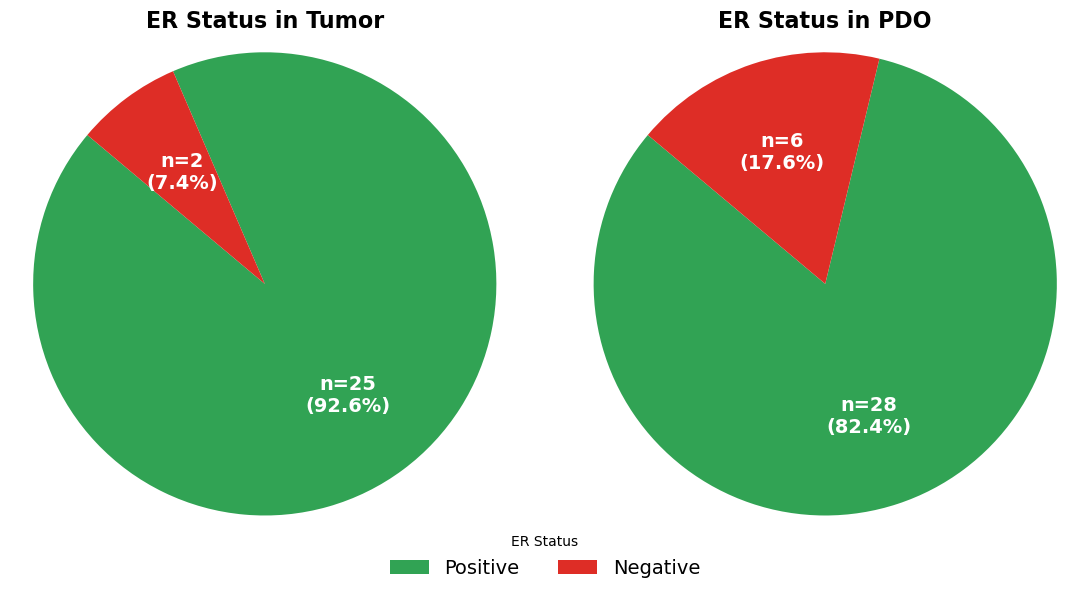

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np  # ✅ for cosine and sine

# File path
file_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/Updated/Bionano_cohort.csv"

# Load dataset
df = pd.read_csv(file_path)

# Clean whitespace
df.columns = df.columns.str.strip()
df['ER Status'] = df['ER Status'].str.strip()
df['Origin'] = df['Origin'].str.strip()

# Define colors
colors = {
    'Positive': '#31a354',
    'Negative': '#de2d26'
}

# Count ER status for Tumor and PDO
tumor_data = df[df['Origin'] == 'Tumor']['ER Status'].value_counts().reindex(['Positive', 'Negative']).fillna(0)
pdo_data = df[df['Origin'] == 'PDO']['ER Status'].value_counts().reindex(['Positive', 'Negative']).fillna(0)

# Choose available data
datasets, titles = [], []
if tumor_data.sum() > 0:
    datasets.append(tumor_data)
    titles.append("Tumor")
if pdo_data.sum() > 0:
    datasets.append(pdo_data)
    titles.append("PDO")

# Exit if no data
if not datasets:
    print("No valid Tumor or PDO data found.")
else:
    # Adjusted figure size: slightly tighter horizontally
    fig, axes = plt.subplots(1, len(datasets), figsize=(5.5 * len(datasets), 6))
    if len(datasets) == 1:
        axes = [axes]

    for ax, data, title in zip(axes, datasets, titles):
        total = int(data.sum())
        wedges, _ = ax.pie(
            data,
            labels=None,  # no labels outside
            startangle=140,
            colors=[colors[k] for k in data.index]
        )

        # Add text labels inside slices
        for i, w in enumerate(wedges):
            count = int(data.iloc[i])
            pct = 100 * count / total if total > 0 else 0
            ang = (w.theta2 + w.theta1) / 2
            x_text = 0.6 * np.cos(np.deg2rad(ang))
            y_text = 0.6 * np.sin(np.deg2rad(ang))
            ax.text(
                x_text, y_text,
                f"n={count}\n({pct:.1f}%)",
                ha='center', va='center',
                fontsize=14, color='white', weight='bold'
            )

        ax.set_title(f"ER Status in {title}", fontsize=16, fontweight='bold')
        ax.axis('equal')

    # Shared legend below both pies
    fig.legend(
        ['Positive', 'Negative'],
        title="ER Status",
        loc='lower center',
        ncol=2,
        frameon=False,
        fontsize=14
    )

    # Adjust layout: make room for legend + reduce space between subplots
    plt.tight_layout(rect=[0, 0.08, 1, 1])
    plt.subplots_adjust(wspace=0.1)  # ✅ reduce space between pie charts

    # Save and show
    plt.savefig("/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/Updated/ER_Status_Tumor_PDO.png", dpi=300)
    plt.show()


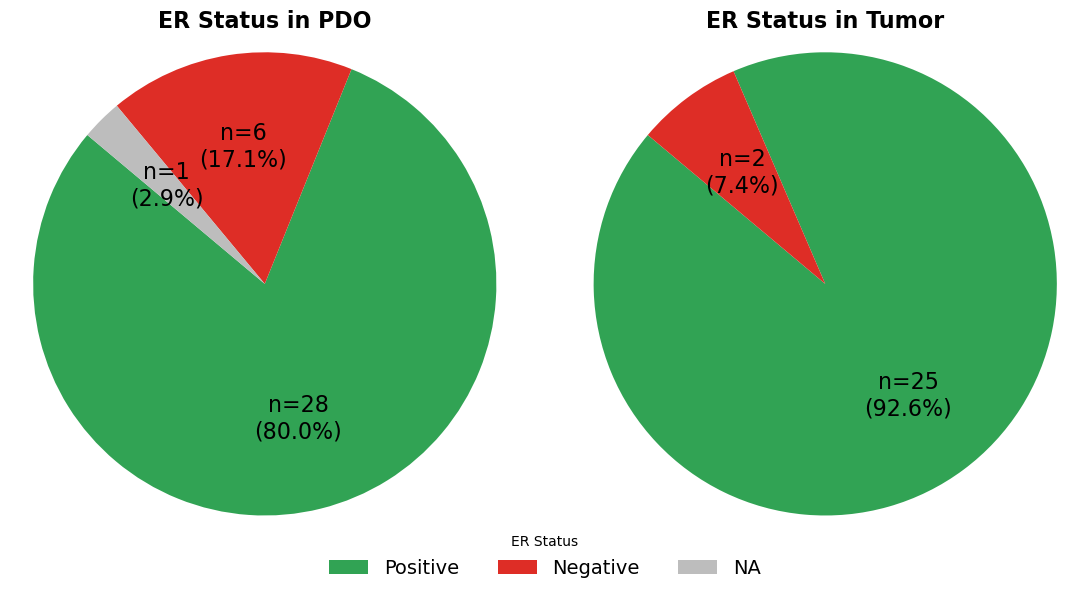

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch

# =============================
# File path
# =============================
file_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/Updated/Bionano_cohort.csv"

# Load dataset
df = pd.read_csv(file_path)

# Clean whitespace
df.columns = df.columns.str.strip()
df['ER Status'] = df['ER Status'].astype(str).str.strip()
df['Origin'] = df['Origin'].str.strip()

# Replace missing or blank entries with "NA"
df['ER Status'].replace(['', 'nan', 'NaN', 'None'], np.nan, inplace=True)
df['ER Status'] = df['ER Status'].fillna('NA')

# =============================
# Define colors
# =============================
colors = {
    'Positive': '#31a354',  # Green
    'Negative': '#de2d26',  # Red
    'NA': '#bdbdbd'         # Gray for missing
}

status_order = ['Positive', 'Negative', 'NA']

# =============================
# Count ER status for Tumor and PDO
# =============================
tumor_data = (
    df[df['Origin'] == 'Tumor']['ER Status']
    .value_counts()
    .reindex(status_order)
    .fillna(0)
)

pdo_data = (
    df[df['Origin'] == 'PDO']['ER Status']
    .value_counts()
    .reindex(status_order)
    .fillna(0)
)

# =============================
# Choose available data
# =============================
datasets, titles = [], []
if pdo_data.sum() > 0:
    datasets.append(pdo_data)
    titles.append("PDO")
if tumor_data.sum() > 0:
    datasets.append(tumor_data)
    titles.append("Tumor")

# =============================
# Plot
# =============================
if not datasets:
    print("No valid Tumor or PDO data found.")
else:
    fig, axes = plt.subplots(1, len(datasets), figsize=(5.5 * len(datasets), 6))
    if len(datasets) == 1:
        axes = [axes]

    for ax, data, title in zip(axes, datasets, titles):
        # ✅ Remove zero categories (so NA won’t appear if absent)
        data_nonzero = data[data > 0]

        total = int(data_nonzero.sum())
        wedges, _ = ax.pie(
            data_nonzero,
            labels=None,
            startangle=140,
            colors=[colors[k] for k in data_nonzero.index]
        )

        # Add inside labels
        for i, w in enumerate(wedges):
            count = int(data_nonzero.iloc[i])
            pct = 100 * count / total if total > 0 else 0
            ang = (w.theta2 + w.theta1) / 2
            x_text = 0.6 * np.cos(np.deg2rad(ang))
            y_text = 0.6 * np.sin(np.deg2rad(ang))
            ax.text(
                x_text, y_text,
                f"n={count}\n({pct:.1f}%)",
                ha='center', va='center',
                fontsize=16, color='black'
            )

        ax.set_title(f"ER Status in {title}", fontsize=16, fontweight='bold')
        ax.axis('equal')

    # =============================
    # ✅ Build legend dynamically (fix color mismatch)
    # =============================
    legend_handles = [Patch(facecolor=colors[s], label=s) for s in status_order]
    fig.legend(
        handles=legend_handles,
        title="ER Status",
        loc='lower center',
        ncol=3,
        frameon=False,
        fontsize=14
    )

    # Adjust layout
    plt.tight_layout(rect=[0, 0.08, 1, 1])
    plt.subplots_adjust(wspace=0.1)

    # Save and show
    plt.savefig("/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/Updated/ER_Status_Tumor_PDO.png", dpi=300)
    plt.show()



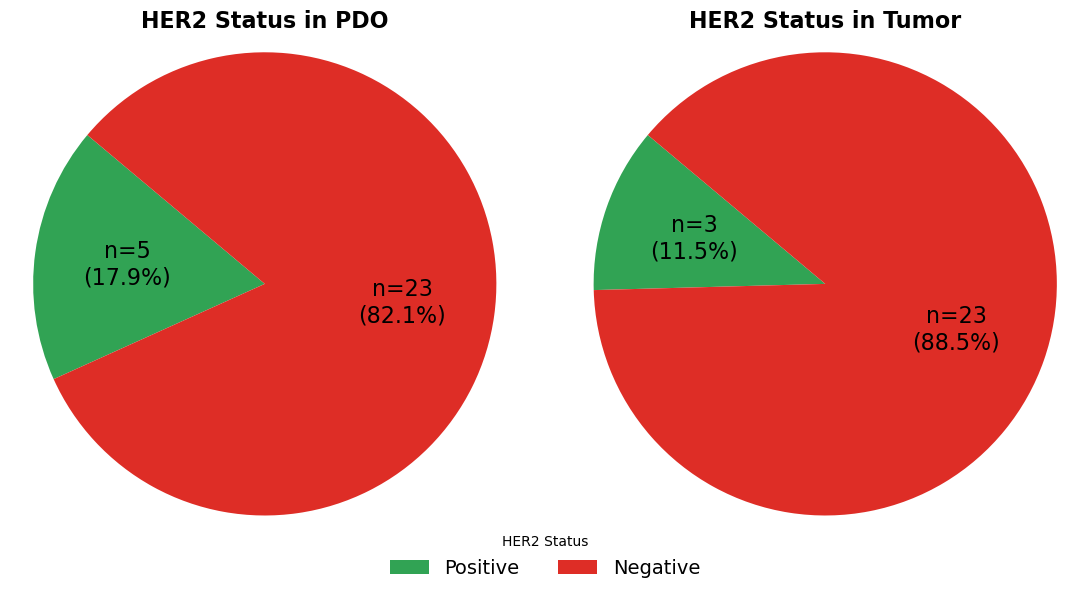

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# File path
file_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/Updated/Bionano_cohort.csv"

# Load dataset
df = pd.read_csv(file_path)

# Clean whitespace
df.columns = df.columns.str.strip()
df['HER2 Status'] = df['HER2 Status'].str.strip()
df['Origin'] = df['Origin'].str.strip()

# Define colors
colors = {
    'Positive': '#31a354',
    'Negative': '#de2d26'
}

# Count HER2 status for Tumor and PDO
tumor_data = df[df['Origin'] == 'Tumor']['HER2 Status'].value_counts().reindex(['Positive', 'Negative']).fillna(0)
pdo_data = df[df['Origin'] == 'PDO']['HER2 Status'].value_counts().reindex(['Positive', 'Negative']).fillna(0)

# Choose available data
datasets, titles = [], []
if pdo_data.sum() > 0:
    datasets.append(pdo_data)
    titles.append("PDO")
if tumor_data.sum() > 0:
    datasets.append(tumor_data)
    titles.append("Tumor")

# Exit if no data
if not datasets:
    print("No valid Tumor or PDO data found for HER2 Status.")
else:
    # Adjusted figure size 
    fig, axes = plt.subplots(1, len(datasets), figsize=(5.5 * len(datasets), 6))
    if len(datasets) == 1:
        axes = [axes]

    for ax, data, title in zip(axes, datasets, titles):
        total = int(data.sum())
        wedges, _ = ax.pie(
            data,
            labels=None,
            startangle=140,
            colors=[colors[k] for k in data.index]
        )

        # Add internal text labels
        for i, w in enumerate(wedges):
            count = int(data.iloc[i])
            pct = 100 * count / total if total > 0 else 0
            ang = (w.theta2 + w.theta1) / 2
            x_text = 0.6 * np.cos(np.deg2rad(ang))
            y_text = 0.6 * np.sin(np.deg2rad(ang))
            ax.text(
                x_text, y_text,
                f"n={count}\n({pct:.1f}%)",
                ha='center', va='center',
                fontsize=16, color='black'
            )

        ax.set_title(f"HER2 Status in {title}", fontsize=16, fontweight='bold')
        ax.axis('equal')

    # Shared legend
    fig.legend(
        ['Positive', 'Negative'],
        title="HER2 Status",
        loc='lower center',
        ncol=2,
        frameon=False,
        fontsize=14
    )

    # Adjust layout and spacing
    plt.tight_layout(rect=[0, 0.08, 1, 1])
    plt.subplots_adjust(wspace=0.1)

    # Save output
    plt.savefig("/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/Updated/HER2_Status_Tumor_PDO.png", dpi=300)
    plt.show()


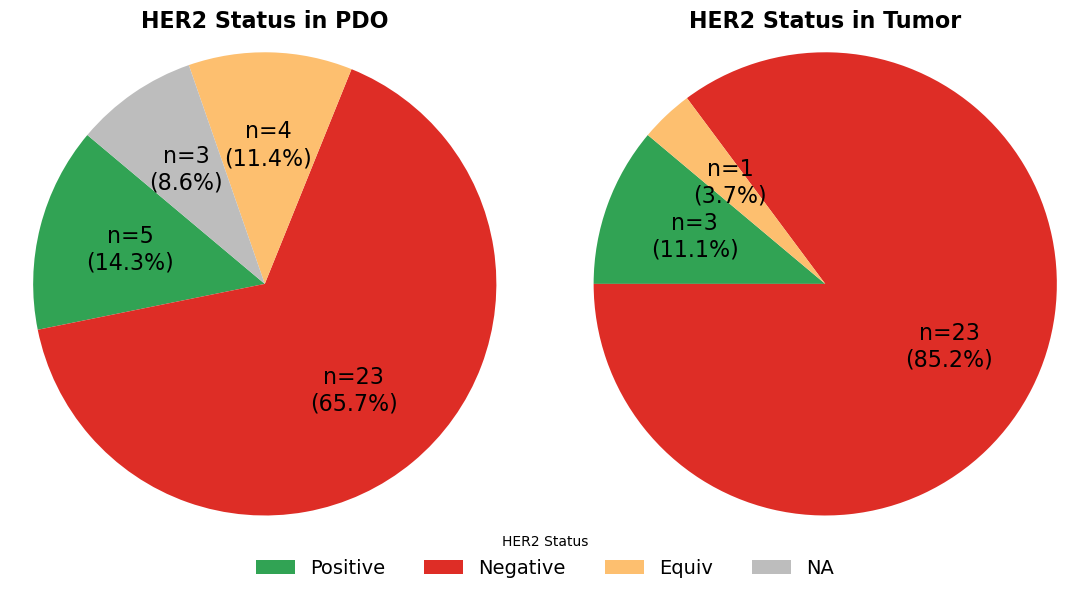

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch

# =============================
# File path
# =============================
file_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/Updated/Bionano_cohort.csv"

# Load dataset
df = pd.read_csv(file_path)

# Clean whitespace
df.columns = df.columns.str.strip()
df['HER2 Status'] = df['HER2 Status'].astype(str).str.strip()
df['Origin'] = df['Origin'].str.strip()

# Replace missing or blank entries with "NA"
df['HER2 Status'].replace(['', 'nan', 'NaN', 'None'], np.nan, inplace=True)
df['HER2 Status'] = df['HER2 Status'].fillna('NA')

# =============================
# Define colors
# =============================
colors = {
    'Positive': '#31a354',   # Green
    'Negative': '#de2d26',   # Red
    'Equiv': '#fdbf6f',      # Yellow-orange
    'NA': '#bdbdbd'          # Gray
}

status_order = ['Positive', 'Negative', 'Equiv', 'NA']

# =============================
# Count HER2 status for Tumor and PDO
# =============================
tumor_data = (
    df[df['Origin'] == 'Tumor']['HER2 Status']
    .value_counts()
    .reindex(status_order)
    .fillna(0)
)

pdo_data = (
    df[df['Origin'] == 'PDO']['HER2 Status']
    .value_counts()
    .reindex(status_order)
    .fillna(0)
)

# =============================
# Choose available data
# =============================
datasets, titles = [], []
if pdo_data.sum() > 0:
    datasets.append(pdo_data)
    titles.append("PDO")
if tumor_data.sum() > 0:
    datasets.append(tumor_data)
    titles.append("Tumor")

# =============================
# Plot
# =============================
if not datasets:
    print("No valid Tumor or PDO data found.")
else:
    fig, axes = plt.subplots(1, len(datasets), figsize=(5.5 * len(datasets), 6))
    if len(datasets) == 1:
        axes = [axes]

    for ax, data, title in zip(axes, datasets, titles):
        # ✅ Filter out zero-count categories
        data_nonzero = data[data > 0]

        total = int(data_nonzero.sum())
        wedges, _ = ax.pie(
            data_nonzero,
            labels=None,
            startangle=140,
            colors=[colors[k] for k in data_nonzero.index]
        )

        # Add inside labels
        for i, w in enumerate(wedges):
            count = int(data_nonzero.iloc[i])
            pct = 100 * count / total if total > 0 else 0
            ang = (w.theta2 + w.theta1) / 2
            x_text = 0.6 * np.cos(np.deg2rad(ang))
            y_text = 0.6 * np.sin(np.deg2rad(ang))
            ax.text(
                x_text, y_text,
                f"n={count}\n({pct:.1f}%)",
                ha='center', va='center',
                fontsize=16, color='black'
            )

        ax.set_title(f"HER2 Status in {title}", fontsize=16, fontweight='bold')
        ax.axis('equal')

    # =============================
    # ✅ Build legend dynamically (fix color mismatch)
    # =============================
    legend_handles = [Patch(facecolor=colors[s], label=s) for s in status_order]
    fig.legend(
        handles=legend_handles,
        title="HER2 Status",
        loc='lower center',
        ncol=4,
        frameon=False,
        fontsize=14
    )

    # Adjust layout
    plt.tight_layout(rect=[0, 0.08, 1, 1])
    plt.subplots_adjust(wspace=0.1)

    # Save and show
    plt.savefig("/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/Updated/HER2_Status_Tumor_PDO.png", dpi=300)
    plt.show()


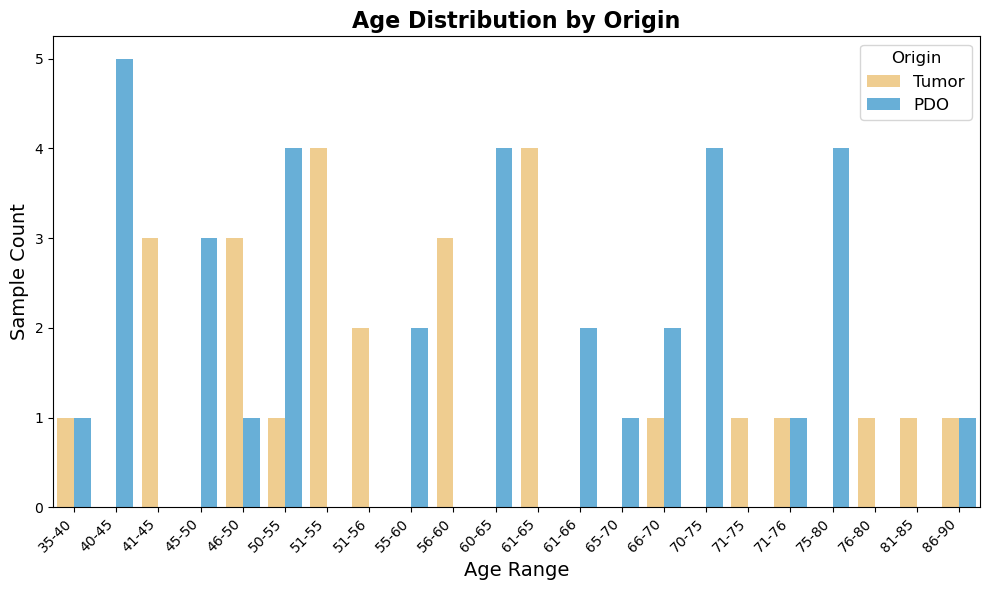

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# =============================
# Load and clean the dataset
# =============================
file_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/Updated/Bionano_cohort.csv"
df = pd.read_csv(file_path)

# Clean whitespace
df.columns = df.columns.str.strip()
df['Origin'] = df['Origin'].str.strip()
df['Age'] = df['Age'].str.strip()

# =============================
# Count samples by Age group and Origin
# =============================
age_counts = df.groupby(['Age', 'Origin']).size().reset_index(name='Count')

# Sort age categories in correct order if possible
age_order = sorted(df['Age'].dropna().unique(),
                   key=lambda x: int(x.split('-')[0]) if '-' in x else 0)

# =============================
# Define consistent colors
# =============================
origin_colors = {
    'Tumor': '#FFD180',  # Peachy-orange
    'PDO': '#56B4E9'     # Light blue
}

# =============================
# Plot setup
# =============================
plt.figure(figsize=(10, 6))
sns.barplot(
    data=age_counts,
    x='Age',
    y='Count',
    hue='Origin',
    hue_order=['Tumor', 'PDO'],
    palette=origin_colors
)

# =============================
# Styling
# =============================
plt.title("Age Distribution by Origin", fontsize=16, fontweight='bold')
plt.xlabel("Age Range", fontsize=14)
plt.ylabel("Sample Count", fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.legend(title="Origin", title_fontsize=12, fontsize=12, loc='upper right')
plt.tight_layout()

# =============================
# Save and display
# =============================
plt.savefig("/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/Updated/Age_Distribution_Tumor_PDO_barplot.png", dpi=300)
plt.show()


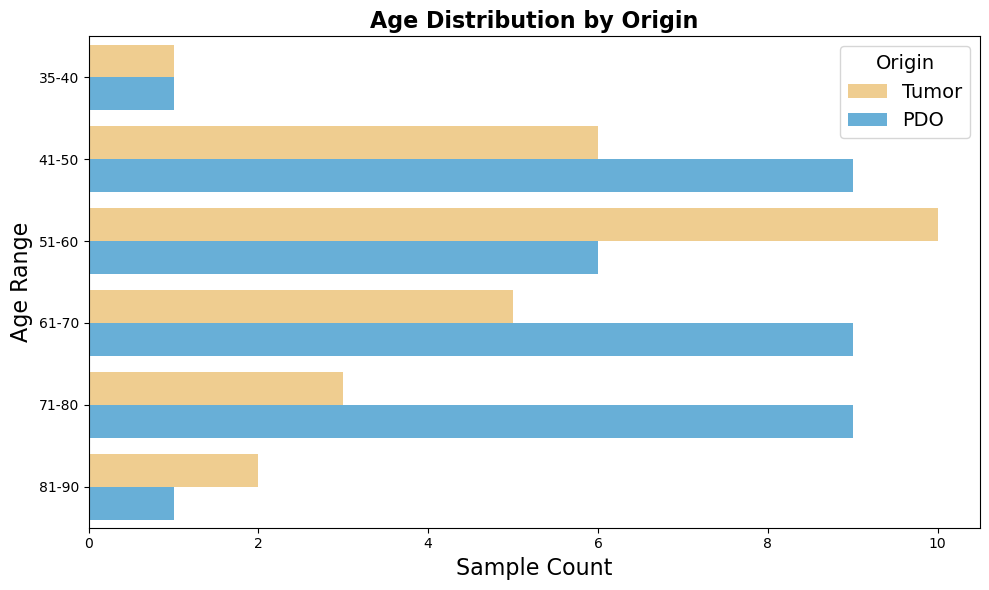

In [29]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# =============================
# Load and clean the dataset
# =============================
file_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/Updated/Bionano_cohort.csv"
df = pd.read_csv(file_path)

# Clean whitespace
df.columns = df.columns.str.strip()
df['Origin'] = df['Origin'].str.strip()
df['Age'] = df['Age'].str.strip()

# =============================
# Count samples by Age and Origin
# =============================
age_counts = df.groupby(['Age', 'Origin']).size().reset_index(name='Count')

# Sort age groups numerically (e.g., 41–45, 46–50, etc.)
age_order = sorted(df['Age'].dropna().unique(),
                   key=lambda x: int(x.split('-')[0]) if '-' in x else 0)

# =============================
# Define colors
# =============================
origin_colors = {
    'Tumor': '#FFD180',  # Peachy-orange
    'PDO': '#56B4E9'     # Light blue
}

# =============================
# Plot: horizontal bar chart
# =============================
plt.figure(figsize=(10, 6))
sns.barplot(
    data=age_counts,
    y='Age',          # Age on Y-axis
    x='Count',        # Count on X-axis
    hue='Origin',
    hue_order=['Tumor', 'PDO'],
    palette=origin_colors,
    order=age_order
)

# =============================
# Styling
# =============================
plt.title("Age Distribution by Origin", fontsize=16, fontweight='bold')
plt.xlabel("Sample Count", fontsize=16)
plt.ylabel("Age Range", fontsize=16)
plt.legend(title="Origin", title_fontsize=14, fontsize=14, loc='upper right')
plt.tight_layout()

# =============================
# Save and show
# =============================
plt.savefig("/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/Updated/Age_Distribution_Tumor_PDO_horizontal_barplot.png", dpi=300)
plt.show()


Plot saved to: /ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/SV_type_counts_Chr_IPM_plot.png


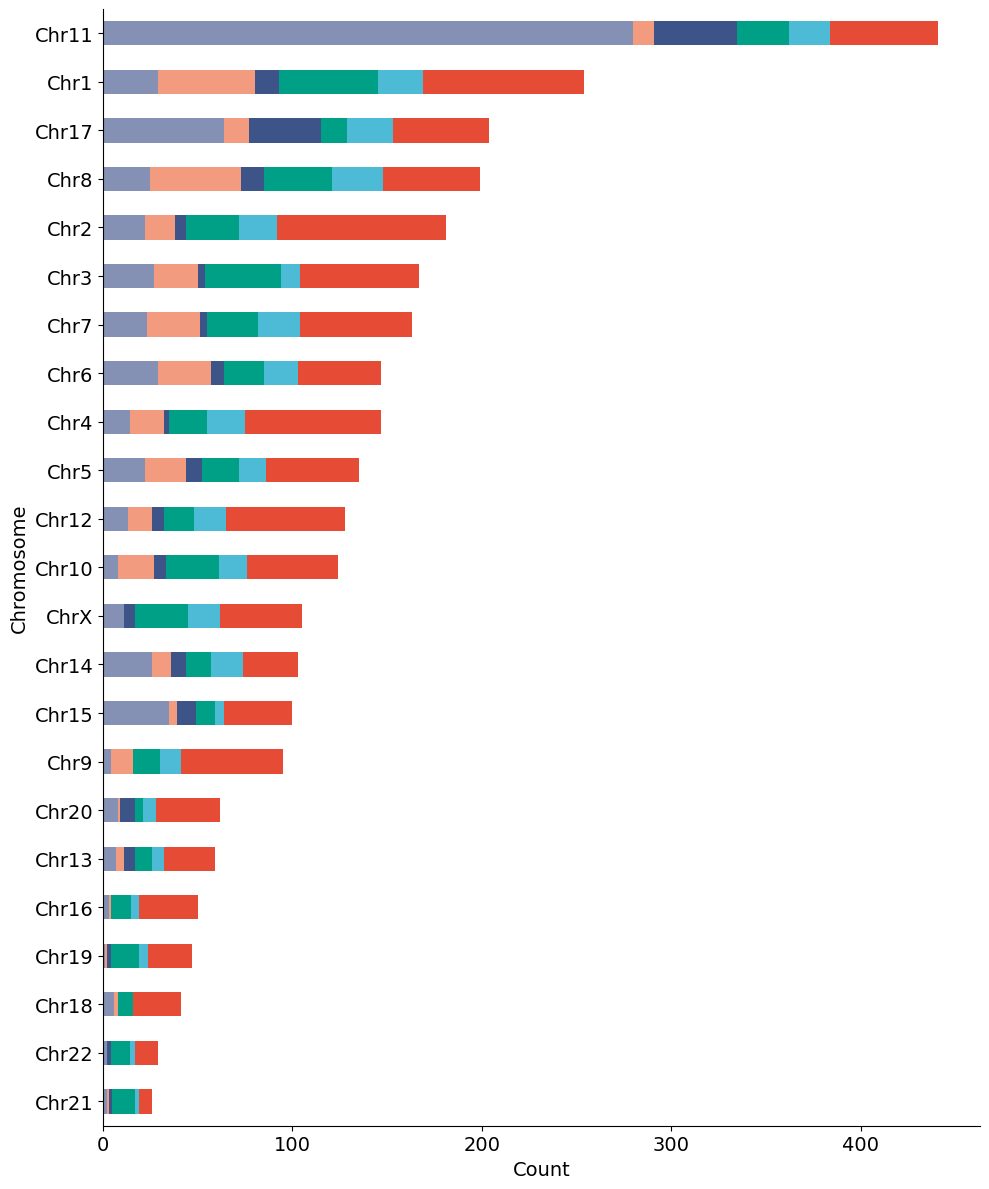

SV_Type
Del               1052
Transloc-Intra     661
Ins                463
Transloc-Inter     326
Dup                310
Inv                195
Name: count, dtype: int64


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# === Load the data ===
file_path = '/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/SV_df_unqiue_SV_count_IPM.csv'
df = pd.read_csv(file_path)

# === Standardize column names (in case of hidden chars like \r) ===
df.columns = [col.strip().replace('\r', '') for col in df.columns]
df.rename(columns={'Chr': 'Chromosome', 'Type': 'SV_Type'}, inplace=True)

# === Strip any whitespace from SV_Type just in case ===
df['SV_Type'] = df['SV_Type'].str.strip()

df['SV_Type'] = df['SV_Type'].replace(
    {r'(?i)^transloc[- ]?intra$': 'Transloc-Intra',
     r'(?i)^transloc[- ]?inter$': 'Transloc-Inter'},
    regex=True
)

# === Group and pivot ===
grouped = df.groupby(['Chromosome', 'SV_Type']).size().unstack(fill_value=0)

# === Define correct SV type order and matching colors ===
sv_order = ['Transloc-Intra', 'Transloc-Inter', 'Inv', 'Ins', 'Dup', 'Del']
npg_colors = {
    'Del': '#E64B35',
    'Dup': '#4DBBD5',
    'Ins': '#00A087',
    'Inv': '#3C5488',
    'Transloc-Inter': '#F39B7F',
    'Transloc-Intra': '#8491B4'
}

# === Reorder only SV types that are present in data ===
present_sv = [sv for sv in sv_order if sv in grouped.columns]
grouped = grouped[present_sv]

# === Sort chromosomes by total SV count (ascending) ===
grouped['Total'] = grouped.sum(axis=1)
grouped_sorted = grouped.sort_values(by='Total', ascending=True).drop(columns='Total')

# === Plot ===
fig, ax = plt.subplots(figsize=(10, 12))
grouped_sorted.plot(
    kind='barh',
    stacked=True,
    ax=ax,
    color=[npg_colors[sv] for sv in grouped_sorted.columns]
)

plt.xlabel("Count", fontsize=14)
plt.ylabel("Chromosome", fontsize=14)
ax.tick_params(axis='both', labelsize=14)
plt.tight_layout()
# plt.legend(title="SV Type", loc='best')
# Remove legend
ax.legend_.remove()
# Keep only bottom (x-axis) and left (y-axis)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# === Save the figure ===
output_file = '/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/SV_type_counts_Chr_IPM_plot.png'
plt.savefig(output_file, dpi=300)
print(f"Plot saved to: {output_file}")

# === Also show the plot interactively ===
plt.show()
print(df['SV_Type'].value_counts(dropna=False))

Plot saved to: /ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/SV_type_counts_Chr_Tumor_plot.png


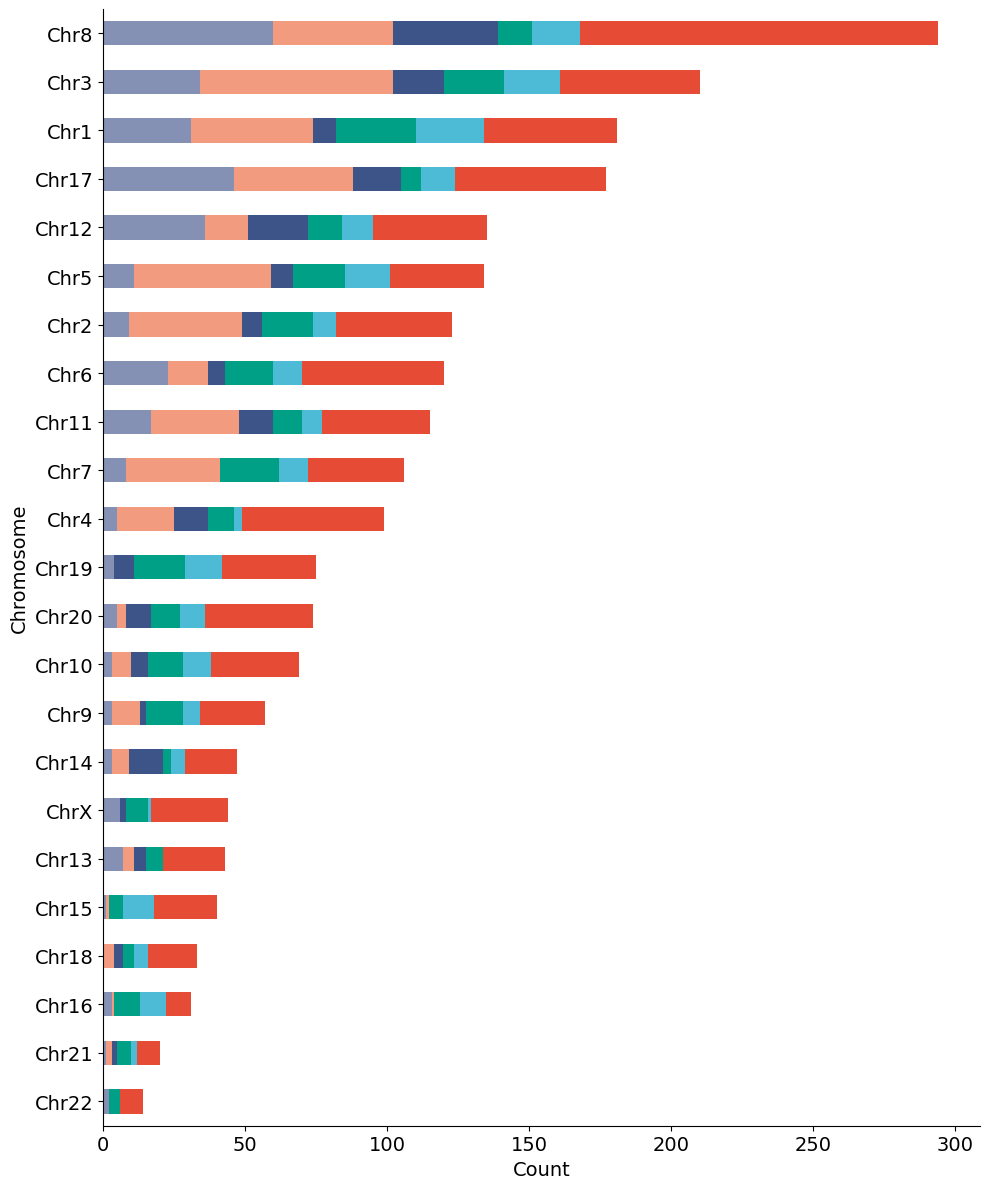

SV_Type
Del               817
Transloc-Inter    434
Transloc-Intra    318
Ins               270
Dup               209
Inv               193
Name: count, dtype: int64


In [3]:
import pandas as pd
import matplotlib.pyplot as plt

# === Load the data ===
file_path = '/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/SV_df_unqiue_SV_count_Tumor.csv'
df = pd.read_csv(file_path)

# === Standardize column names (in case of hidden chars like \r) ===
df.columns = [col.strip().replace('\r', '') for col in df.columns]
df.rename(columns={'Chr': 'Chromosome', 'Type': 'SV_Type'}, inplace=True)

# === Strip any whitespace from SV_Type just in case ===
df['SV_Type'] = df['SV_Type'].str.strip()

df['SV_Type'] = df['SV_Type'].replace(
    {r'(?i)^transloc[- ]?intra$': 'Transloc-Intra',
     r'(?i)^transloc[- ]?inter$': 'Transloc-Inter'},
    regex=True
)

# === Group and pivot ===
grouped = df.groupby(['Chromosome', 'SV_Type']).size().unstack(fill_value=0)

# === Define correct SV type order and matching colors ===
sv_order = ['Transloc-Intra', 'Transloc-Inter', 'Inv', 'Ins', 'Dup', 'Del']
npg_colors = {
    'Del': '#E64B35',
    'Dup': '#4DBBD5',
    'Ins': '#00A087',
    'Inv': '#3C5488',
    'Transloc-Inter': '#F39B7F',
    'Transloc-Intra': '#8491B4'
}

# === Reorder only SV types that are present in data ===
present_sv = [sv for sv in sv_order if sv in grouped.columns]
grouped = grouped[present_sv]

# === Sort chromosomes by total SV count (ascending) ===
grouped['Total'] = grouped.sum(axis=1)
grouped_sorted = grouped.sort_values(by='Total', ascending=True).drop(columns='Total')

# === Plot ===
fig, ax = plt.subplots(figsize=(10, 12))
grouped_sorted.plot(
    kind='barh',
    stacked=True,
    ax=ax,
    color=[npg_colors[sv] for sv in grouped_sorted.columns]
)

plt.xlabel("Count", fontsize=14)
plt.ylabel("Chromosome", fontsize=14)
ax.tick_params(axis='both', labelsize=14)
plt.tight_layout()
# plt.legend(title="SV Type", loc='best')
# Remove legend
ax.legend_.remove()
# Keep only bottom (x-axis) and left (y-axis)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# === Save the figure ===
output_file = '/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/SV_type_counts_Chr_Tumor_plot.png'
plt.savefig(output_file, dpi=300)
print(f"Plot saved to: {output_file}")

# === Also show the plot interactively ===
plt.show()
print(df['SV_Type'].value_counts(dropna=False))

Fusion plot saved to: /bgfs/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/SV_df_Tumor_Inter_Translocation_plot.png


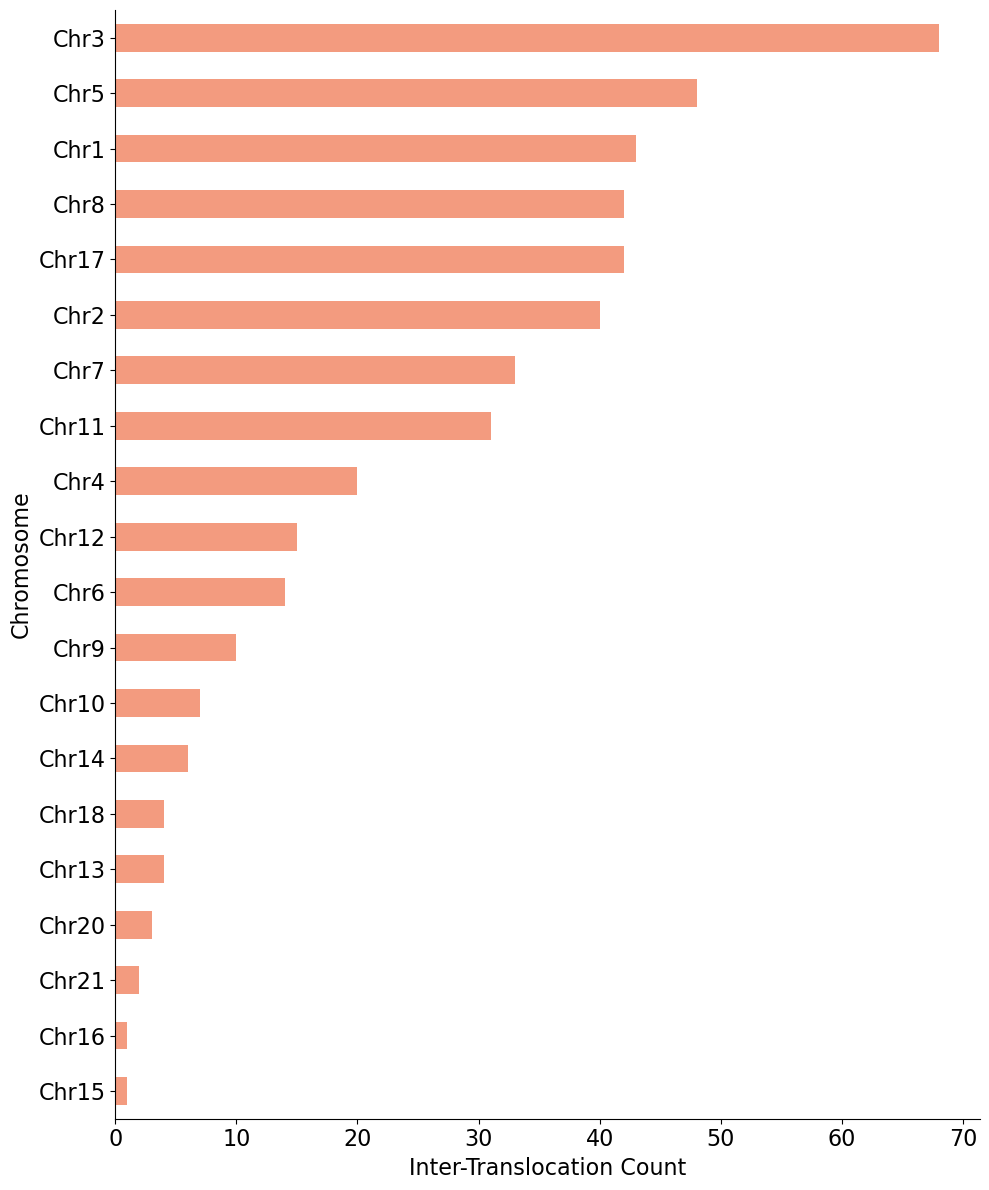

In [14]:
import pandas as pd
import matplotlib.pyplot as plt

# === Load data ===
file_path = '/bgfs/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/SV_df_unqiue_SV_count_Tumor.csv'
df = pd.read_csv(file_path)

# === Standardize column names ===
df.columns = [col.strip().replace('\r', '') for col in df.columns]
df.rename(columns={'Chr': 'Chromosome', 'Type': 'SV_Type'}, inplace=True)
df['SV_Type'] = df['SV_Type'].str.strip()

# === Filter only Fusion types ===
fusion_df = df[df['SV_Type'].isin(['Transloc-Inter'])].copy()

# === Label them both as 'Fusion' ===
fusion_df['SV_Type'] = 'Fusion'

# === Count Fusions per Chromosome ===
fusion_counts = fusion_df.groupby('Chromosome').size().sort_values(ascending=True)

# === Plot ===
fig, ax = plt.subplots(figsize=(10, 12))
fusion_counts.plot(
    kind='barh',
    color='#F39B7F',  # Navy blue from ggsci palette (you can change)
    ax=ax
)

# Keep only x and y axis lines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.xlabel("Inter-Translocation Count", fontsize=16)
plt.ylabel("Chromosome", fontsize=16)
ax.tick_params(axis='both', labelsize=16)
plt.tight_layout()

# === Save plot ===
output_file = '/bgfs/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/SV_df_Tumor_Inter_Translocation_plot.png'
plt.savefig(output_file, dpi=300)
print(f"Fusion plot saved to: {output_file}")

plt.show()


Fusion plot saved to: /bgfs/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/SV_df_IPM_Inter_Translocation_plot.png


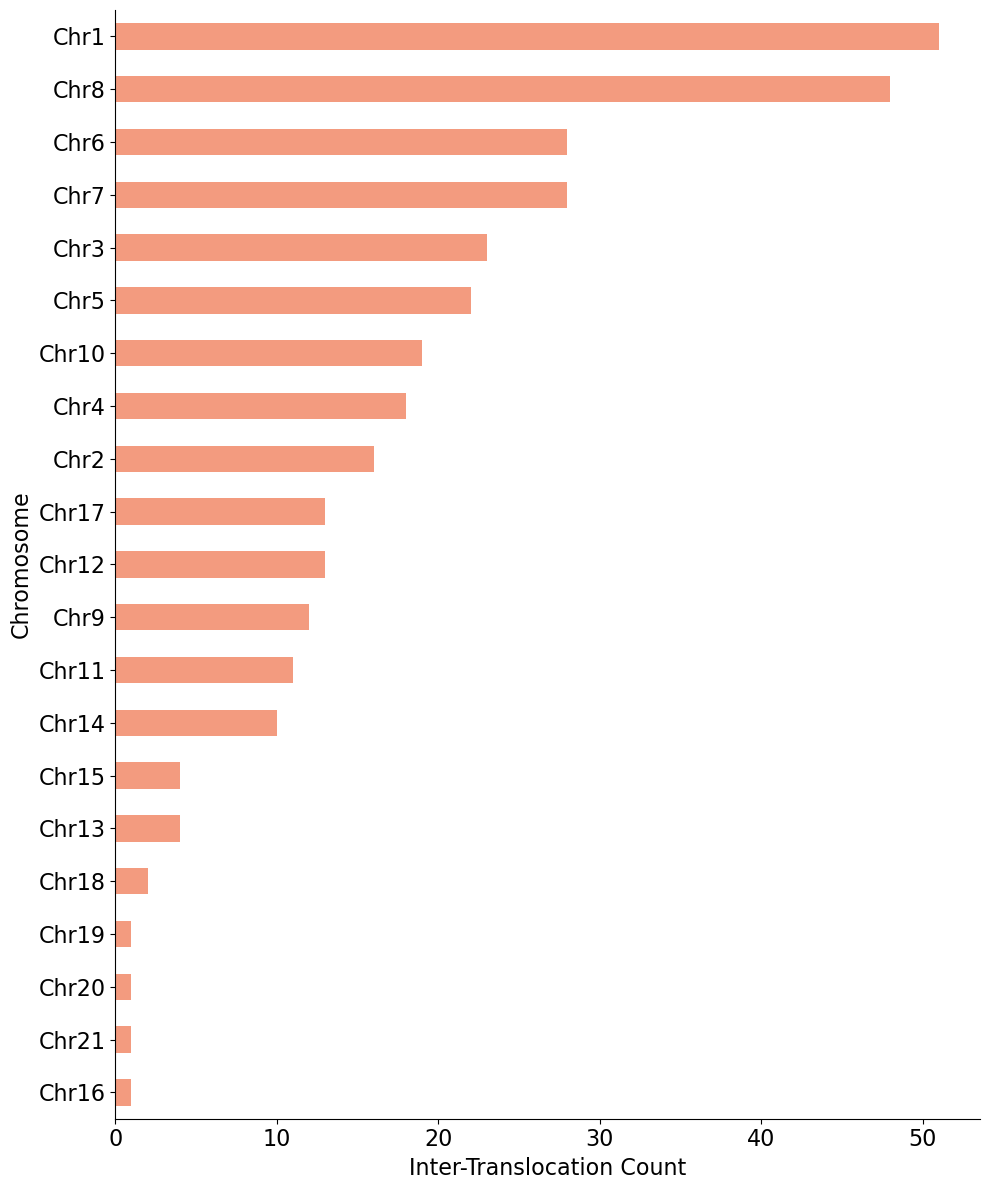

In [17]:
import pandas as pd
import matplotlib.pyplot as plt

# === Load data ===
file_path = '/bgfs/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/SV_df_unqiue_SV_count_IPM.csv'
df = pd.read_csv(file_path)

# === Standardize column names ===
df.columns = [col.strip().replace('\r', '') for col in df.columns]
df.rename(columns={'Chr': 'Chromosome', 'Type': 'SV_Type'}, inplace=True)
df['SV_Type'] = df['SV_Type'].str.strip()

# === Filter only Fusion types ===
fusion_df = df[df['SV_Type'].isin(['Transloc-Inter'])].copy()

# === Label them both as 'Fusion' ===
fusion_df['SV_Type'] = 'Fusion'

# === Count Fusions per Chromosome ===
fusion_counts = fusion_df.groupby('Chromosome').size().sort_values(ascending=True)

# === Plot ===
fig, ax = plt.subplots(figsize=(10, 12))
fusion_counts.plot(
    kind='barh',
    color='#F39B7F',  # Navy blue from ggsci palette (you can change)
    ax=ax
)

# Keep only x and y axis lines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.xlabel("Inter-Translocation Count", fontsize=16)
plt.ylabel("Chromosome", fontsize=16)
ax.tick_params(axis='both', labelsize=16)
plt.tight_layout()

# === Save plot ===
output_file = '/bgfs/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/SV_df_IPM_Inter_Translocation_plot.png'
plt.savefig(output_file, dpi=300)
print(f"Fusion plot saved to: {output_file}")

plt.show()


Plot saved to: /bgfs/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/DNA_IPM_SV_Count_plot.png


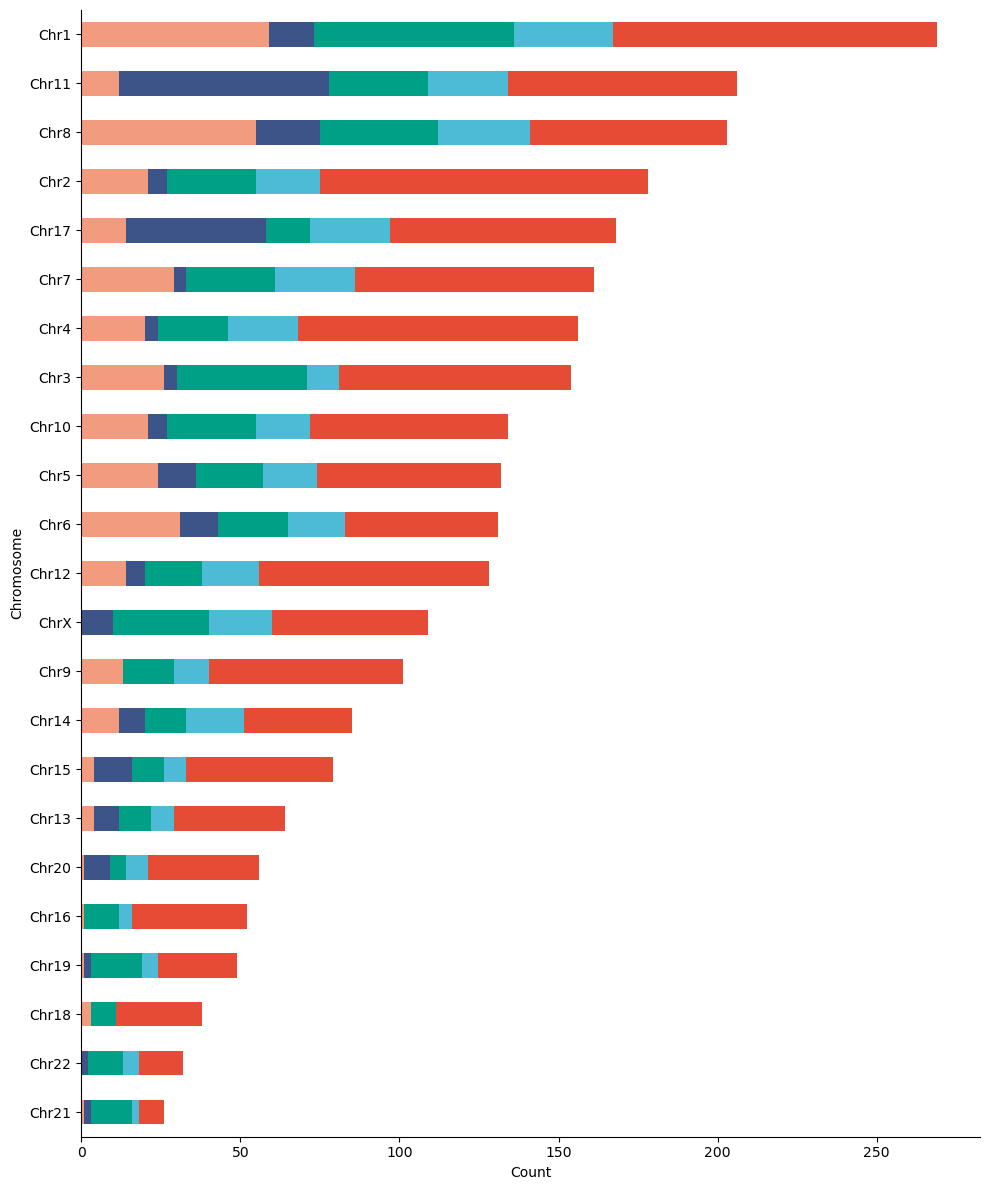

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# === Load the data ===
file_path = '/bgfs/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/DNA_SV_Count_IPM.csv'
df = pd.read_csv(file_path)

# === Standardize column names (in case of hidden chars like \r) ===
df.columns = [col.strip().replace('\r', '') for col in df.columns]
df.rename(columns={'Chr': 'Chromosome', 'Type': 'SV_Type'}, inplace=True)

# === Strip any whitespace from SV_Type just in case ===
df['SV_Type'] = df['SV_Type'].str.strip()

# === Group and pivot ===
grouped = df.groupby(['Chromosome', 'SV_Type']).size().unstack(fill_value=0)

# === Define correct SV type order and matching colors ===
sv_order = ['Transloc-Intra', 'Transloc-Inter', 'Inv', 'Ins', 'Dup', 'Del']
npg_colors = {
    'Del': '#E64B35',
    'Dup': '#4DBBD5',
    'Ins': '#00A087',
    'Inv': '#3C5488',
    'Transloc-Inter': '#F39B7F',
    'Transloc-Intra': '#8491B4'
}

# === Reorder only SV types that are present in data ===
present_sv = [sv for sv in sv_order if sv in grouped.columns]
grouped = grouped[present_sv]

# === Sort chromosomes by total SV count (ascending) ===
grouped['Total'] = grouped.sum(axis=1)
grouped_sorted = grouped.sort_values(by='Total', ascending=True).drop(columns='Total')

# === Plot ===
fig, ax = plt.subplots(figsize=(10, 12))
grouped_sorted.plot(
    kind='barh',
    stacked=True,
    ax=ax,
    color=[npg_colors[sv] for sv in grouped_sorted.columns]
)

plt.xlabel("Count")
plt.ylabel("Chromosome")
# plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
# plt.legend(title="SV Type", loc='best')
# Remove legend
ax.legend_.remove()
# Keep only bottom (x-axis) and left (y-axis)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# === Save the figure ===
output_file = '/bgfs/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/DNA_IPM_SV_Count_plot.png'
plt.savefig(output_file, dpi=300)
print(f"Plot saved to: {output_file}")

# === Also show the plot interactively ===
plt.show()

Plot saved to: /bgfs/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/DNA_Tumor_SV_Count_plot.png


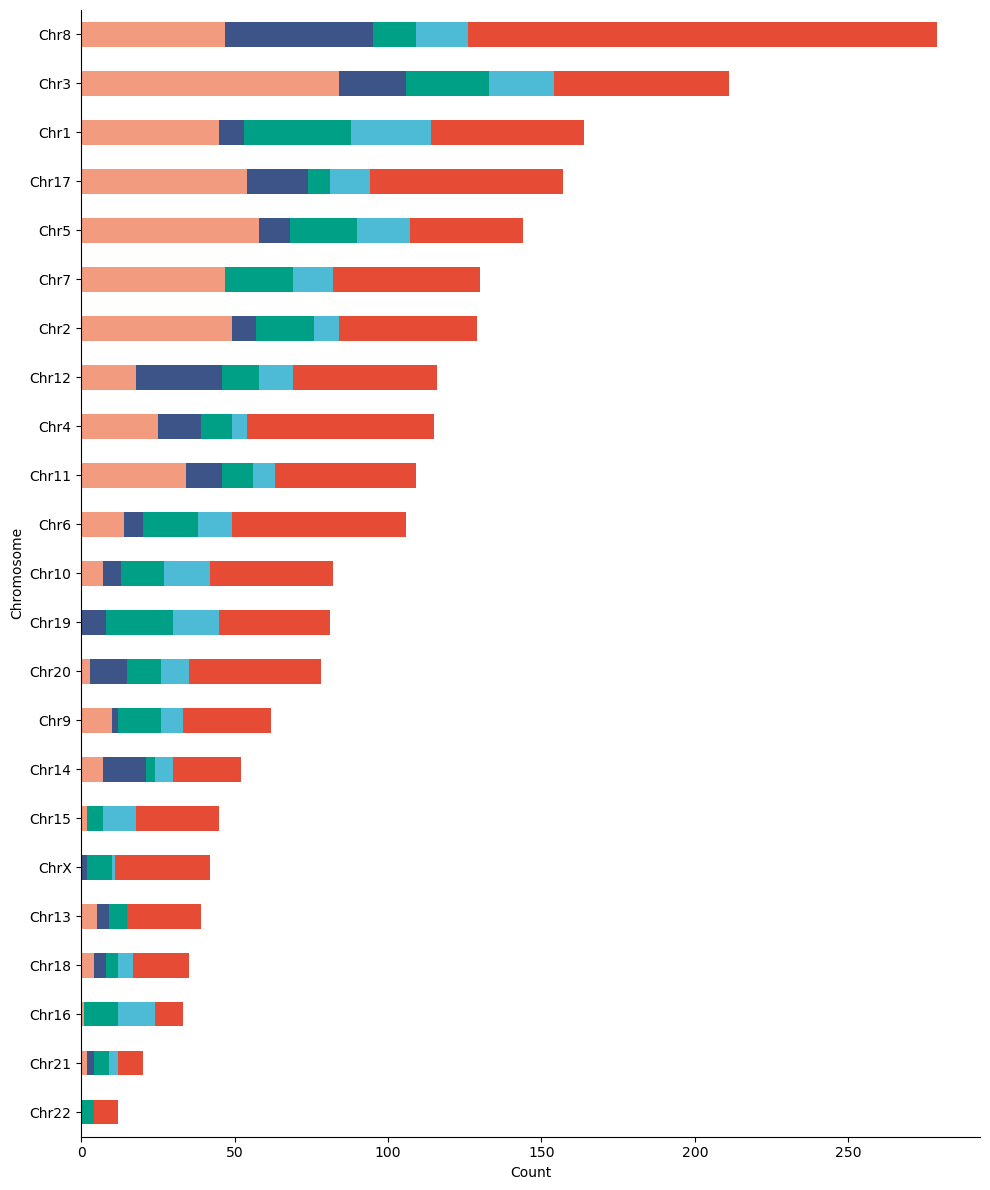

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# === Load the data ===
file_path = '/bgfs/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/DNA_SV_Count_Tumor.csv'
df = pd.read_csv(file_path)

# === Standardize column names (in case of hidden chars like \r) ===
df.columns = [col.strip().replace('\r', '') for col in df.columns]
df.rename(columns={'Chr': 'Chromosome', 'Type': 'SV_Type'}, inplace=True)

# === Strip any whitespace from SV_Type just in case ===
df['SV_Type'] = df['SV_Type'].str.strip()

# === Group and pivot ===
grouped = df.groupby(['Chromosome', 'SV_Type']).size().unstack(fill_value=0)

# === Define correct SV type order and matching colors ===
sv_order = ['Transloc-Intra', 'Transloc-Inter', 'Inv', 'Ins', 'Dup', 'Del']
npg_colors = {
    'Del': '#E64B35',
    'Dup': '#4DBBD5',
    'Ins': '#00A087',
    'Inv': '#3C5488',
    'Transloc-Inter': '#F39B7F',
    'Transloc-Intra': '#8491B4'
}

# === Reorder only SV types that are present in data ===
present_sv = [sv for sv in sv_order if sv in grouped.columns]
grouped = grouped[present_sv]

# === Sort chromosomes by total SV count (ascending) ===
grouped['Total'] = grouped.sum(axis=1)
grouped_sorted = grouped.sort_values(by='Total', ascending=True).drop(columns='Total')

# === Plot ===
fig, ax = plt.subplots(figsize=(10, 12))
grouped_sorted.plot(
    kind='barh',
    stacked=True,
    ax=ax,
    color=[npg_colors[sv] for sv in grouped_sorted.columns]
)

plt.xlabel("Count")
plt.ylabel("Chromosome")
# plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()

# plt.legend(title="SV Type", loc='best')
# Remove legend
ax.legend_.remove()

# Keep only bottom (x-axis) and left (y-axis)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# === Save the figure ===
output_file = '/bgfs/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/DNA_Tumor_SV_Count_plot.png'
plt.savefig(output_file, dpi=300)
print(f"Plot saved to: {output_file}")

# === Also show the plot interactively ===
plt.show()

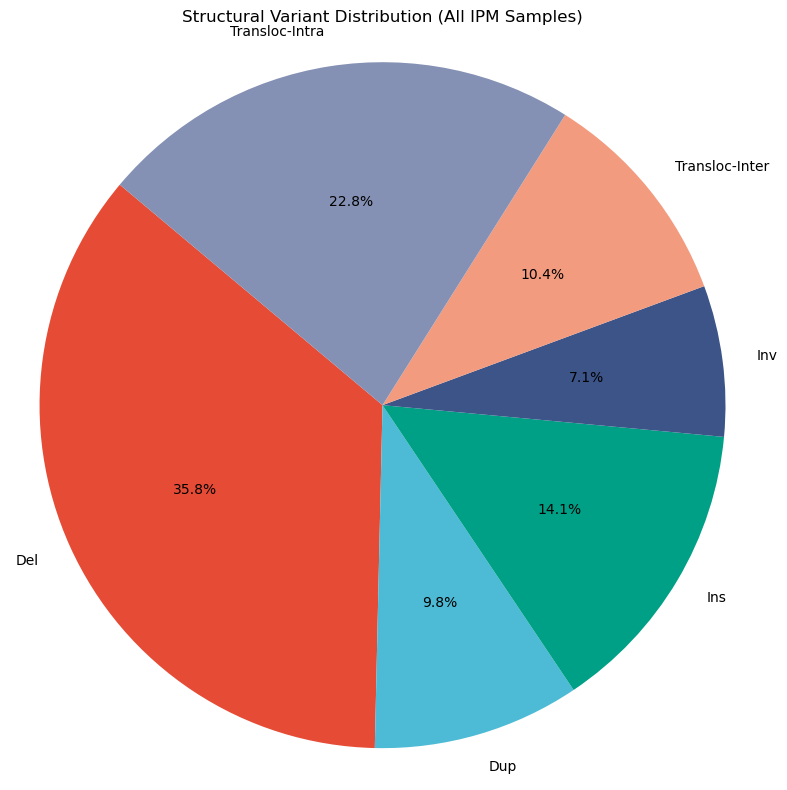

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

# File path to the new raw SV data
file_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/DNA_SV_Count_IPM.csv"

# Load the dataset
df = pd.read_csv(file_path)

# Count each SV type across all samples
sv_totals = df['Type'].value_counts().sort_index()

# Define consistent colors for known SV types
colors = {
    'Del': '#E64B35',
    'Dup': '#4DBBD5',
    'Ins': '#00A087',
    'Inv': '#3C5488',
    'Transloc-Inter': '#F39B7F',
    'Transloc-Intra': '#8491B4'
}

# Ensure only SV types with defined colors are plotted
sv_totals = sv_totals[sv_totals.index.isin(colors.keys())]

# Plot the pie chart
plt.figure(figsize=(8, 8))
plt.pie(
    sv_totals,
    labels=sv_totals.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=[colors[sv] for sv in sv_totals.index]
)
plt.title("Structural Variant Distribution (All IPM Samples)")
plt.axis('equal')
plt.tight_layout()

# Save the pie chart
output_path = "/bgfs/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/DNA_IPM_SV_distribution_piechart.png"
plt.savefig(output_path, dpi=300)

# Display the chart
plt.show()


Total SV count: 3513


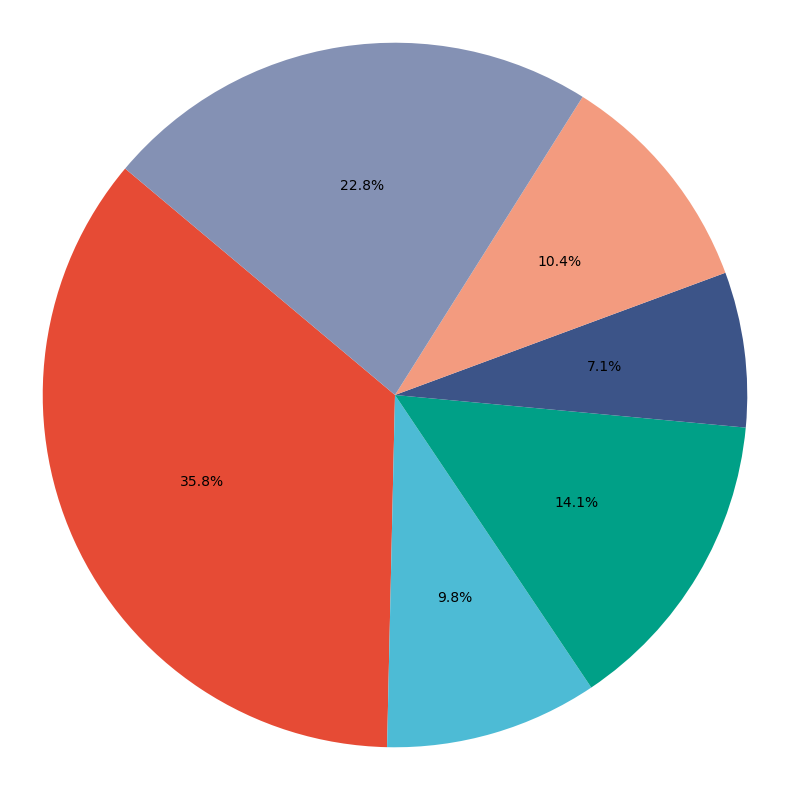

In [14]:
import pandas as pd
import matplotlib.pyplot as plt

# File path to the new raw SV data
file_path = "/bgfs/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/DNA_SV_Count_IPM.csv"

# Load the dataset
df = pd.read_csv(file_path)

# Count each SV type across all samples
sv_totals = df['Type'].value_counts().sort_index()

# Define consistent colors for known SV types
colors = {
    'Del': '#E64B35',
    'Dup': '#4DBBD5',
    'Ins': '#00A087',
    'Inv': '#3C5488',
    'Transloc-Inter': '#F39B7F',
    'Transloc-Intra': '#8491B4'
}

# Ensure only SV types with defined colors are plotted
sv_totals = sv_totals[sv_totals.index.isin(colors.keys())]

print(f"Total SV count: {sv_totals.sum()}")


# Plot the pie chart
plt.figure(figsize=(8, 8))
plt.pie(
    sv_totals,
    # labels=sv_totals.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=[colors[sv] for sv in sv_totals.index]
)
plt.axis('equal')
plt.tight_layout()

# Save the pie chart
output_path = "/bgfs/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/DNA_IPM_SV_distribution_piechart.png"
plt.savefig(output_path, dpi=300)

# Display the chart
plt.show()


Total SV count: 2595


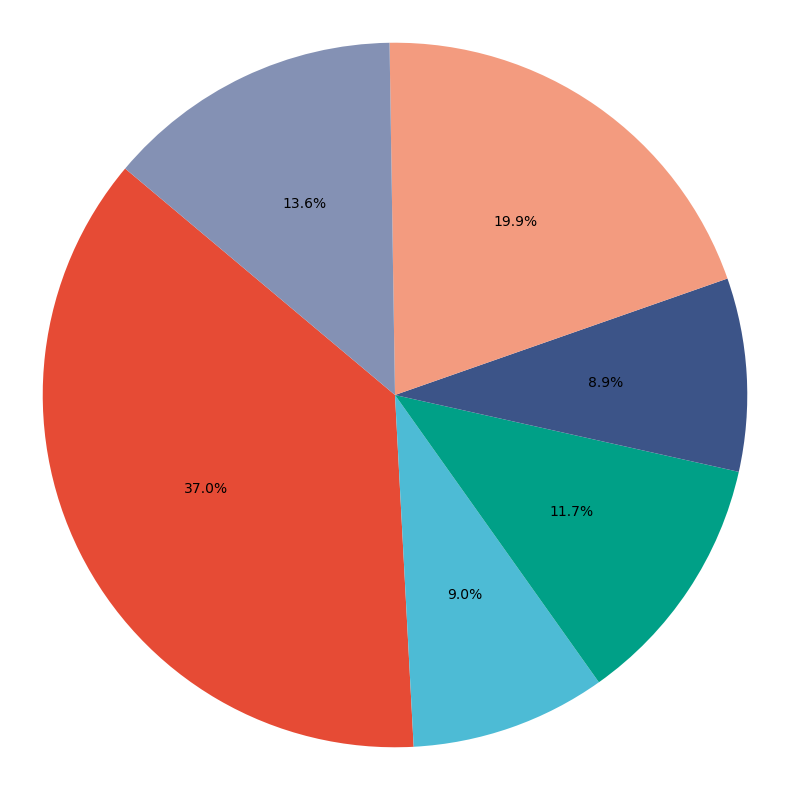

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

# File path to the new raw SV data
file_path = "/bgfs/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/DNA_SV_Count_Tumor.csv"

# Load the dataset
df = pd.read_csv(file_path)

# Count each SV type across all samples
sv_totals = df['Type'].value_counts().sort_index()

# Define consistent colors for known SV types
colors = {
    'Del': '#E64B35',
    'Dup': '#4DBBD5',
    'Ins': '#00A087',
    'Inv': '#3C5488',
    'Transloc-Inter': '#F39B7F',
    'Transloc-Intra': '#8491B4'
}

# Ensure only SV types with defined colors are plotted
sv_totals = sv_totals[sv_totals.index.isin(colors.keys())]

print(f"Total SV count: {sv_totals.sum()}")

# Plot the pie chart
plt.figure(figsize=(8, 8))
plt.pie(
    sv_totals,
    # labels=sv_totals.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=[colors[sv] for sv in sv_totals.index]
)
plt.axis('equal')
plt.tight_layout()

# Save the pie chart
output_path = "/bgfs/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/DNA_Tumor_SV_distribution_piechart.png"
plt.savefig(output_path, dpi=300)

# Display the chart
plt.show()


Total SV count: 2346


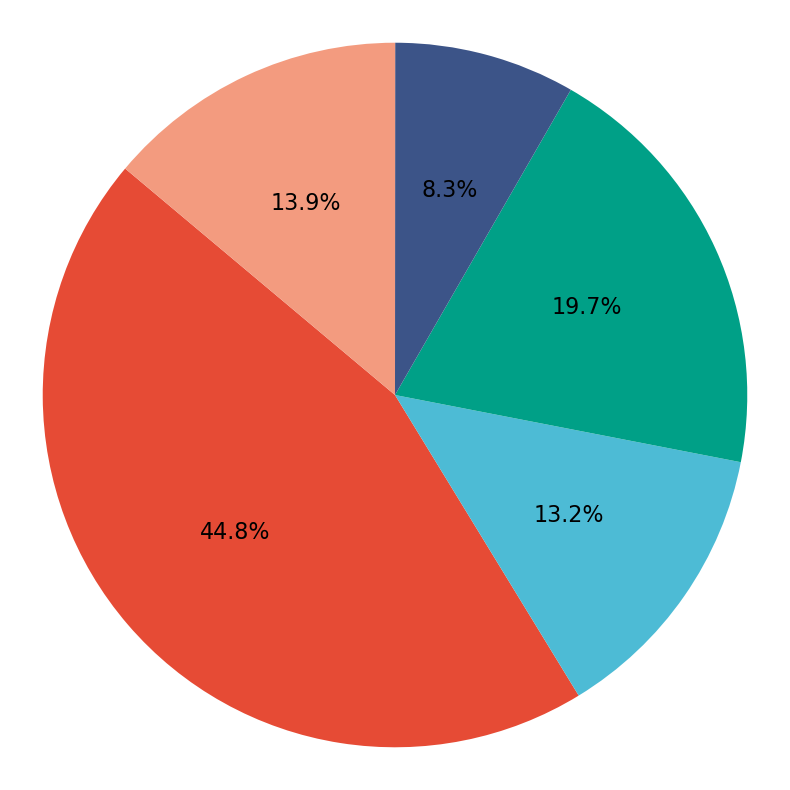

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

# File path to the new raw SV data
file_path = "/bgfs/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/SV_df_unqiue_SV_count_IPM.csv"

# Load the dataset
df = pd.read_csv(file_path)

# Count each SV type across all samples
sv_totals = df['Type'].value_counts().sort_index()

# Define consistent colors for known SV types
colors = {
    'Del': '#E64B35',
    'Dup': '#4DBBD5',
    'Ins': '#00A087',
    'Inv': '#3C5488',
    'Transloc-Inter': '#F39B7F',
    'Transloc-Intra': '#8491B4'
}

# Ensure only SV types with defined colors are plotted
sv_totals = sv_totals[sv_totals.index.isin(colors.keys())]

print(f"Total SV count: {sv_totals.sum()}")


# Plot the pie chart
plt.figure(figsize=(8, 8))
plt.pie(
    sv_totals,
    autopct='%1.1f%%',
    startangle=140,
    colors=[colors[sv] for sv in sv_totals.index],
    textprops={'fontsize': 16}
)

plt.axis('equal')
plt.tight_layout()

# Save the pie chart
output_path = "/bgfs/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/SV_df_IPM_SV_distribution_piechart.png"
plt.savefig(output_path, dpi=300)

# Display the chart
plt.show()


Total SV count: 1923


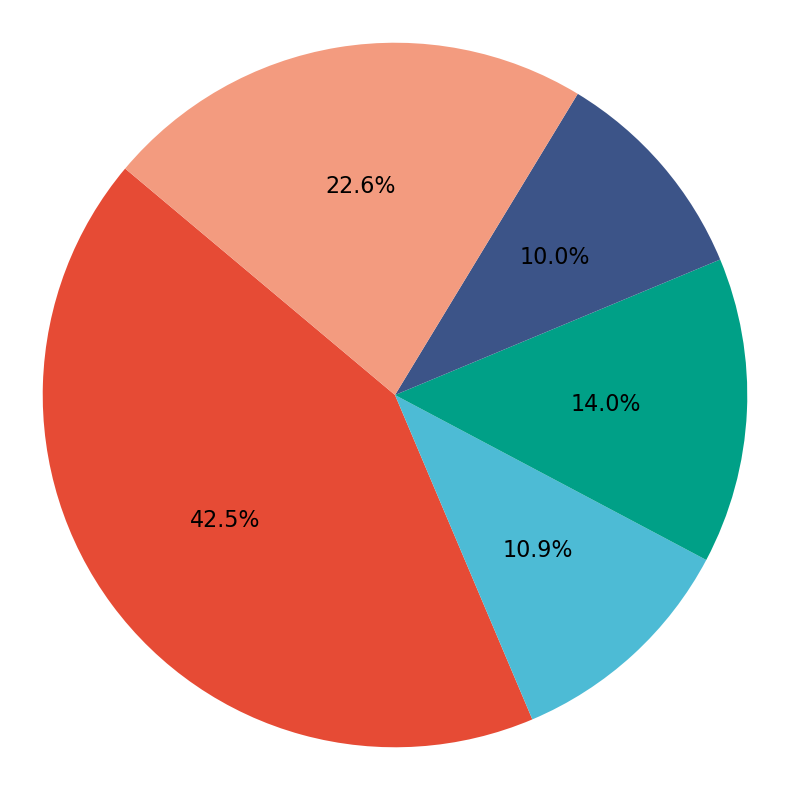

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

# File path to the new raw SV data
file_path = "/bgfs/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/SV_df_unqiue_SV_count_Tumor.csv"

# Load the dataset
df = pd.read_csv(file_path)

# Count each SV type across all samples
sv_totals = df['Type'].value_counts().sort_index()

# Define consistent colors for known SV types
colors = {
    'Del': '#E64B35',
    'Dup': '#4DBBD5',
    'Ins': '#00A087',
    'Inv': '#3C5488',
    'Transloc-Inter': '#F39B7F',
    'Transloc-Intra': '#8491B4'
}

# Ensure only SV types with defined colors are plotted
sv_totals = sv_totals[sv_totals.index.isin(colors.keys())]

print(f"Total SV count: {sv_totals.sum()}")


# Plot the pie chart
plt.figure(figsize=(8, 8))
plt.pie(
    sv_totals,
    autopct='%1.1f%%',
    startangle=140,
    colors=[colors[sv] for sv in sv_totals.index],
    textprops={'fontsize': 16}
)

plt.axis('equal')
plt.tight_layout()

# Save the pie chart
output_path = "/bgfs/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/SV_df_Tumor_SV_distribution_piechart.png"
plt.savefig(output_path, dpi=300)

# Display the chart
plt.show()


In [28]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# === CONFIG ===
file_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/SV_df_unqiue.csv"
chr_col = "Chr"
start_col = "RefStartPos"
end_col = "RefEndPos"
sample_col = "sample"

# === COLORS AND LEGEND LABELS ===
colors = {
    "Both breakpoints recurrent": "#0072B2",  # Blue
    "One breakpoint recurrent": "#E69F00",    # Orange
    "Not recurrent": "#999999",               # Grey
}

legend_labels = {
    "Both breakpoints recurrent": "both breakpoints\nin another sample",
    "One breakpoint recurrent": "one breakpoint\nin another sample",
    "Not recurrent": "not recurrent"
}

# === LOAD AND CLEAN DATA ===
print("Loading data...")
try:
    df = pd.read_csv(file_path, low_memory=False)
    df.columns = [col.strip().replace('\r', '') for col in df.columns]
    df = df[[chr_col, start_col, end_col, sample_col]].dropna()

    # Convert to numeric
    df[start_col] = pd.to_numeric(df[start_col], errors='coerce')
    df[end_col] = pd.to_numeric(df[end_col], errors='coerce')
    df = df.dropna()

except FileNotFoundError:
    print(f"Error: The file {file_path} was not found.")
    exit()
except Exception as e:
    print(f"Error during data loading: {e}")
    exit()

if df.empty:
    print("Error: The dataset is empty after preprocessing.")
    exit()

# === SPLIT DATA INTO PDO AND TUMOR ===
print("Splitting data...")
pdo_df = df[df[sample_col].str.startswith("IPM", na=False)].copy()
tumor_df = df[df[sample_col].str.startswith("TP", na=False)].copy()

if pdo_df.empty and tumor_df.empty:
    print("Error: No PDO or Tumor samples found in the dataset.")
    exit()

# === RECURRING CLASSIFICATION FUNCTION ===

# Allowable slop for breakpoint matching
slop = 10

def classify_recurrence(df_subset):
    def single_row_classify(row, group_df):
        sample = row[sample_col]
        chr_ = row[chr_col]
        start = row[start_col]
        end = row[end_col]
        others = group_df[(group_df[sample_col] != sample) & (group_df[chr_col] == chr_)]

        both_rec = others[((others[start_col] >= start - slop) & (others[start_col] <= start + slop)) &
                          ((others[end_col] >= end - slop) & (others[end_col] <= end + slop))]

        start_rec = others[(others[start_col] >= start - slop) & (others[start_col] <= start + slop)]
        end_rec = others[(others[end_col] >= end - slop) & (others[end_col] <= end + slop)]

        if len(both_rec) > 0:
            return "Both breakpoints recurrent"
        elif len(start_rec) > 0 or len(end_rec) > 0:
            return "One breakpoint recurrent"
        else:
            return "Not recurrent"

    recurrence_results = []
    for chrom, group in df_subset.groupby(chr_col):
        rec = group.apply(lambda row: single_row_classify(row, group), axis=1)
        recurrence_results.append(rec)

    if not recurrence_results:
        return pd.Series(dtype=str)

    return pd.concat(recurrence_results)

# === CLASSIFY RECURRENCE ===
print("Classifying recurrence...")
pdo_df['Recurrence'] = classify_recurrence(pdo_df)
tumor_df['Recurrence'] = classify_recurrence(tumor_df)

# === SAVE RESULTS TO CSV ===
pdo_output_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/PDO_SV_breakpoint_recurrence.csv"
tumor_output_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/Tumor_SV_breakpoint_recurrence.csv"

pdo_df.to_csv(pdo_output_path, index=False)
tumor_df.to_csv(tumor_output_path, index=False)

print(f"Saved PDO data to {pdo_output_path}")
print(f"Saved Tumor data to {tumor_output_path}")

# === PLOTTING FUNCTION ===
# === SEPARATE PLOTS FOR PDO, TUMOR, AND LEGEND ===
def plot_recurrence_separately(pdo_df, tumor_df, output_prefix):
    valid_classes = list(colors.keys())

    # --- Count classes for each group ---
    pdo_counts = pdo_df['Recurrence'].value_counts().reindex(valid_classes, fill_value=0)
    tumor_counts = tumor_df['Recurrence'].value_counts().reindex(valid_classes, fill_value=0)

    # === Helper: make a single pie and save ===
    def save_pie(data_counts, title, output_file):
        fig, ax = plt.subplots(figsize=(6, 6))
        wedges, _ = ax.pie(
            data_counts,
            labels=None,
            colors=[colors[k] for k in data_counts.index],
            startangle=140
        )
        ax.text(
            0, -1.25,
            f"n={data_counts.sum():,} SVs\n{title} Samples",
            ha='center', va='center',
            fontsize=14, fontweight='bold'
        )
        ax.axis('equal')
        plt.tight_layout()
        plt.savefig(output_file, dpi=300)
        plt.close(fig)
        print(f"✅ Saved {output_file}")

    # --- PDO pie ---
    save_pie(pdo_counts, "PDO", f"{output_prefix}_PDO_pie.png")

    # --- Tumor pie ---
    save_pie(tumor_counts, "Tumor", f"{output_prefix}_Tumor_pie.png")

    # --- Legend only ---
    legend_handles = [Patch(facecolor=colors[k], label=legend_labels[k]) for k in valid_classes]
    fig_leg, ax_leg = plt.subplots(figsize=(3.5, 3.5))
    ax_leg.axis("off")
    ax_leg.legend(
        handles=legend_handles,
        loc="center",
        fontsize=13,
        title="SV breakpoint\nposition recurrence",
        title_fontsize=14,
        frameon=False
    )
    plt.tight_layout()
    plt.savefig(f"{output_prefix}_Legend.png", dpi=300)
    plt.close(fig_leg)
    print(f"✅ Saved {output_prefix}_Legend.png")
    
    # === RUN FINAL SEPARATE PLOTS ===
output_prefix = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/SV_df_SV_recurrence_PDO_vs_Tumor"
print("Generating separate figures...")
plot_recurrence_separately(pdo_df, tumor_df, output_prefix)
print("✅ All plots generated successfully.")



Loading data...
Splitting data...
Classifying recurrence...
Saved PDO data to /ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/PDO_SV_breakpoint_recurrence.csv
Saved Tumor data to /ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/Tumor_SV_breakpoint_recurrence.csv
Generating separate figures...
✅ Saved /ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/SV_df_SV_recurrence_PDO_vs_Tumor_PDO_pie.png
✅ Saved /ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/SV_df_SV_recurrence_PDO_vs_Tumor_Tumor_pie.png
✅ Saved /ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/SV_df_SV_recurrence_PDO_vs_Tumor_Legend.png
✅ All plots generated successfully.


In [6]:
import pandas as pd

# === CONFIG ===
file_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/SV_df_unqiue.csv"
chr_col = "Chr"
start_col = "RefStartPos"
end_col = "RefEndPos"
sample_col = "sample"

# Breakpoint to check
target_chr = "Chr1"
target_start = 83171695
target_end = 83186312
target_sample = "IPM-BO-019"

# Allowable slop for breakpoint matching
slop = 10

# === LOAD DATA ===
df = pd.read_csv(file_path, low_memory=False)
df.columns = [col.strip().replace('\r', '') for col in df.columns]
df = df[[chr_col, start_col, end_col, sample_col]].dropna()

# Convert to numeric
df[start_col] = pd.to_numeric(df[start_col], errors='coerce')
df[end_col] = pd.to_numeric(df[end_col], errors='coerce')
df = df.dropna()

# Filter to relevant chromosome and exclude the target sample
df_filtered = df[(df[chr_col] == target_chr) & (df[sample_col] != target_sample)]

# === CHECK RECURRENCE ===
# Check for both breakpoints
both_rec = df_filtered[(df_filtered[start_col].between(target_start - slop, target_start + slop)) &
                       (df_filtered[end_col].between(target_end - slop, target_end + slop))]

# Check for start breakpoint only
start_rec = df_filtered[df_filtered[start_col].between(target_start - slop, target_start + slop)]

# Check for end breakpoint only
end_rec = df_filtered[df_filtered[end_col].between(target_end - slop, target_end + slop)]

# === OUTPUT RESULTS ===
print("\nChecking recurrence for breakpoint in sample:")
print(f"Chr: {target_chr}, Start: {target_start}, End: {target_end}, Sample: {target_sample}\n")

if len(both_rec) > 0:
    print("Both breakpoints found in the following samples:")
    print(both_rec[[sample_col, start_col, end_col]])
else:
    print("No matching SVs found for both breakpoints.")

if len(start_rec) > 0:
    print("\nStart breakpoint found in the following samples:")
    print(start_rec[[sample_col, start_col, end_col]])
else:
    print("No matching start breakpoint found.")

if len(end_rec) > 0:
    print("\nEnd breakpoint found in the following samples:")
    print(end_rec[[sample_col, start_col, end_col]])
else:
    print("No matching end breakpoint found.")



Checking recurrence for breakpoint in sample:
Chr: Chr1, Start: 83171695, End: 83186312, Sample: IPM-BO-019

Both breakpoints found in the following samples:
          sample  RefStartPos  RefEndPos
2792  IPM-BO-174     83171695   83186312
2989  IPM-BO-189     83171695   83186312

Start breakpoint found in the following samples:
          sample  RefStartPos  RefEndPos
2792  IPM-BO-174     83171695   83186312
2989  IPM-BO-189     83171695   83186312

End breakpoint found in the following samples:
          sample  RefStartPos  RefEndPos
2792  IPM-BO-174     83171695   83186312
2989  IPM-BO-189     83171695   83186312


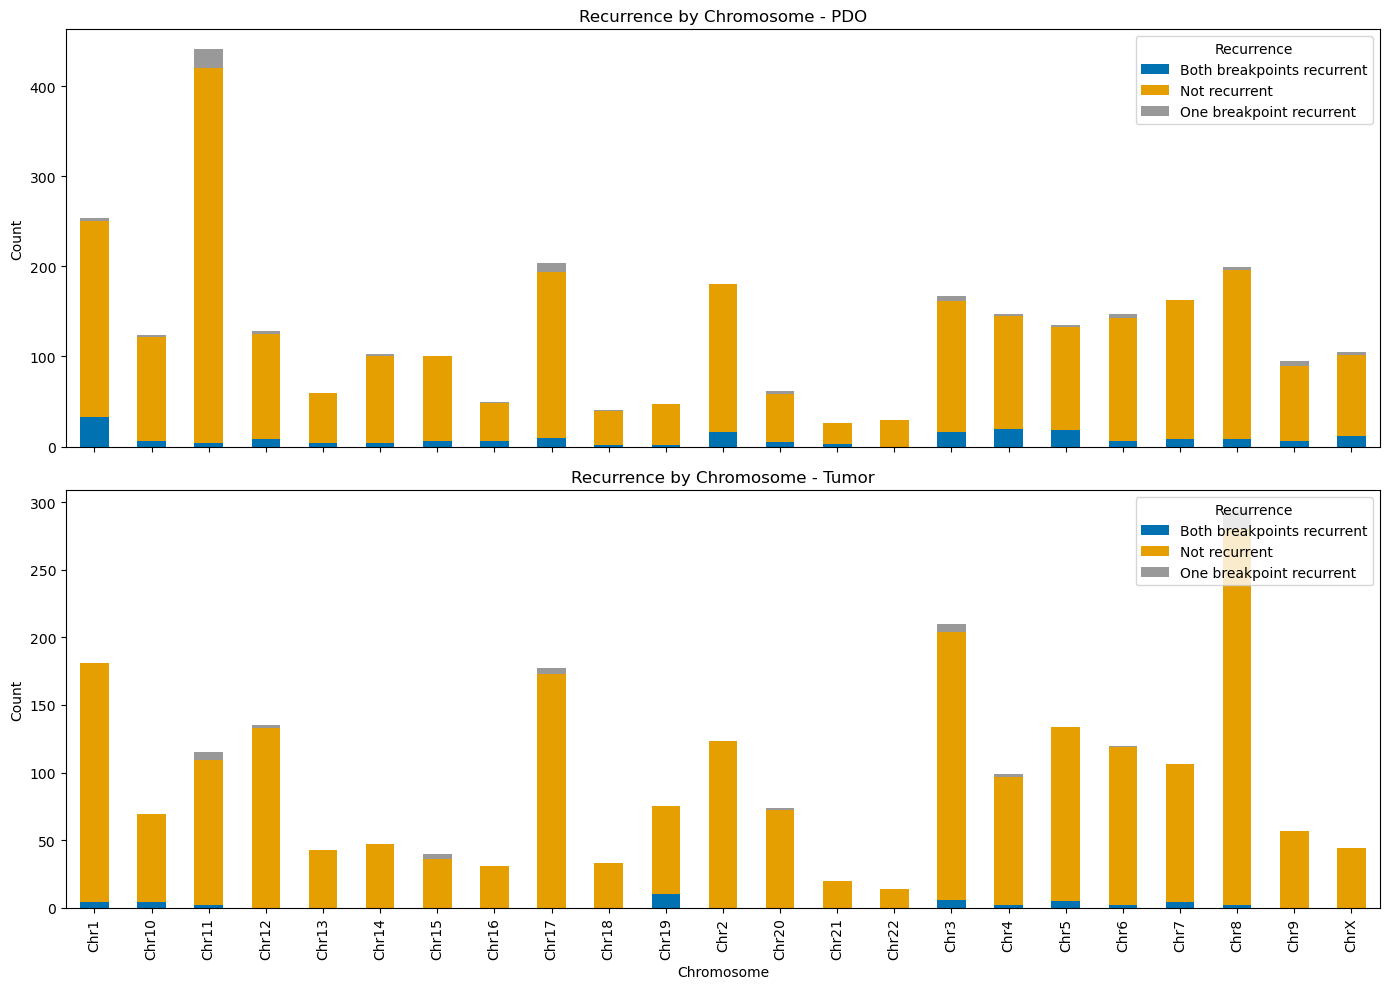

Most Common Breakpoints - PDO
Most Common Breakpoints:
        Chr  RefStartPos  RefEndPos  Count
131    Chr1    144173283  144201874      3
72     Chr1     83171695   83186312      3
2529   Chr8     15919069   15931293      3
1740  Chr21     10326071   10330635      3
1703  Chr20     16681624   16694271      3
198    Chr1    208273500  208285657      3
839   Chr12     44935967   50369270      2
1629   Chr2    160755864  160775695      2
2088   Chr4    189678394  189789718      2
1561   Chr2     87654355   87683090      2
Most Common Breakpoints - Tumor
Most Common Breakpoints:
        Chr  RefStartPos  RefEndPos  Count
921   Chr19     46520475   46523206      5
924   Chr19     49015337   49065744      3
1490   Chr5     14993191   15008321      3
1606   Chr6     19486002   19499359      2
2035   Chr8     69945525   69956979      2
50     Chr1     49550727   49568265      2
1721   Chr7     13543500   13551919      2
227   Chr10     74605127   74617381      2
1361   Chr3    186701501  18

In [9]:
##################################################################################################
## SV breakpoint recurrence 

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# === CONFIG ===
file_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/SV_df_unqiue.csv"
chr_col = "Chr"
start_col = "RefStartPos"
end_col = "RefEndPos"
sample_col = "sample"

# === COLORS AND LEGEND LABELS ===
colors = {
    "Both breakpoints recurrent": "#0072B2",
    "One breakpoint recurrent": "#E69F00",
    "Not recurrent": "#999999",
}

legend_labels = {
    "Both breakpoints recurrent": "both breakpoints\nin another sample",
    "One breakpoint recurrent": "one breakpoint\nin another sample",
    "Not recurrent": "not recurrent"
}

# === LOAD AND CLEAN DATA ===
df = pd.read_csv(file_path, low_memory=False)
df.columns = [col.strip().replace('\r', '') for col in df.columns]
df = df[[chr_col, start_col, end_col, sample_col]].dropna()

df[start_col] = pd.to_numeric(df[start_col], errors='coerce')
df[end_col] = pd.to_numeric(df[end_col], errors='coerce')
df = df.dropna()

# === RECURRING CLASSIFICATION FUNCTION ===
slop = 10

def classify_recurrence(df_subset):
    def single_row_classify(row, group_df):
        sample = row[sample_col]
        chr_ = row[chr_col]
        start = row[start_col]
        end = row[end_col]
        others = group_df[(group_df[sample_col] != sample) & (group_df[chr_col] == chr_)]

        both_rec = others[((others[start_col] >= start - slop) & (others[start_col] <= start + slop)) &
                          ((others[end_col] >= end - slop) & (others[end_col] <= end + slop))]
        start_rec = others[(others[start_col] >= start - slop) & (others[start_col] <= start + slop)]
        end_rec = others[(others[end_col] >= end - slop) & (others[end_col] <= end + slop)]

        if len(both_rec) > 0:
            return "Both breakpoints recurrent"
        elif len(start_rec) > 0 or len(end_rec) > 0:
            return "One breakpoint recurrent"
        else:
            return "Not recurrent"

    recurrence_results = []
    for chrom, group in df_subset.groupby(chr_col):
        rec = group.apply(lambda row: single_row_classify(row, group), axis=1)
        recurrence_results.append(rec)

    return pd.concat(recurrence_results)

# Apply the classification
pdo_df['Recurrence'] = classify_recurrence(pdo_df)
tumor_df['Recurrence'] = classify_recurrence(tumor_df)

# === PLOT RECURRENCE BY CHROMOSOME ===
def plot_recurrence_by_chromosome(pdo_df, tumor_df, output_file):
    fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)
    chromosomes = sorted(pdo_df[chr_col].unique())

    for ax, df, label in zip(axes, [pdo_df, tumor_df], ["PDO", "Tumor"]):
        counts = df.groupby([chr_col, 'Recurrence']).size().unstack(fill_value=0)
        counts = counts.reindex(chromosomes).fillna(0)
        counts.plot(kind='bar', stacked=True, color=[colors[k] for k in colors.keys()], ax=ax)
        ax.set_title(f"Recurrence by Chromosome - {label}")
        ax.set_ylabel("Count")
        ax.legend(title="Recurrence", loc='upper right')

    plt.xlabel("Chromosome")
    plt.tight_layout()
    plt.savefig(output_file, dpi=300)
    plt.show()

# === RUN CHROMOSOME PLOT ===
plot_recurrence_by_chromosome(
    pdo_df,
    tumor_df,
    "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/SV_Chromosome_Recurrent_PDO_vs_Tumor.png"
)
# === IDENTIFY MOST COMMON BREAKPOINT ===
def identify_most_common_breakpoint(df):
    breakpoint_counts = df.groupby([chr_col, start_col, end_col]).size().reset_index(name='Count')
    most_common = breakpoint_counts.sort_values(by='Count', ascending=False).head(10)
    print("Most Common Breakpoints:")
    print(most_common)
    return most_common

# Identify most common breakpoints for PDO and Tumor
print("Most Common Breakpoints - PDO")
most_common_pdo = identify_most_common_breakpoint(pdo_df)

print("Most Common Breakpoints - Tumor")
most_common_tumor = identify_most_common_breakpoint(tumor_df)


=== PDO Samples SV Summary ===
Total samples: 35
Max SVs per sample: 348.0
Mean SVs per sample: 85.91
Min SVs per sample: 3.0
Total SVs (all samples): 3,007


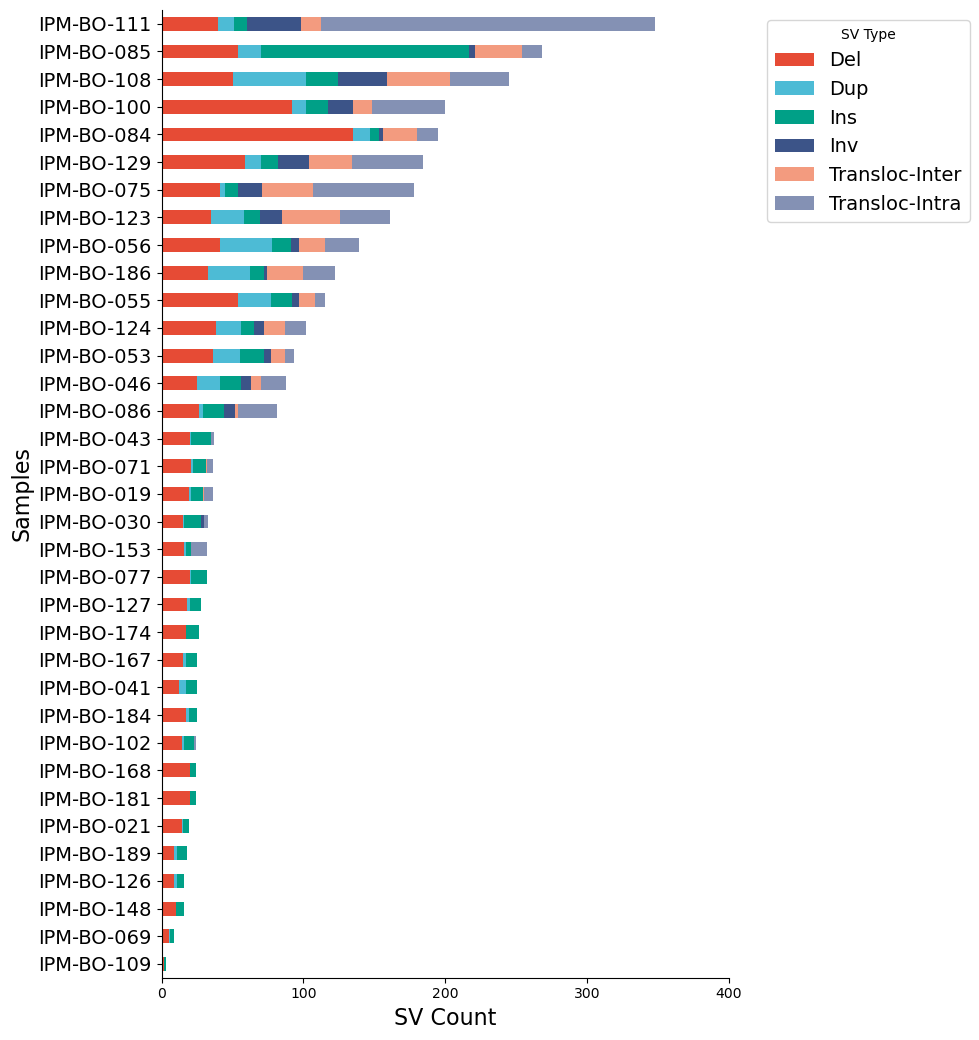


=== Tumor Samples SV Summary ===
Total samples: 27
Max SVs per sample: 595.0
Mean SVs per sample: 83.00
Min SVs per sample: 7.0
Total SVs (all samples): 2,241


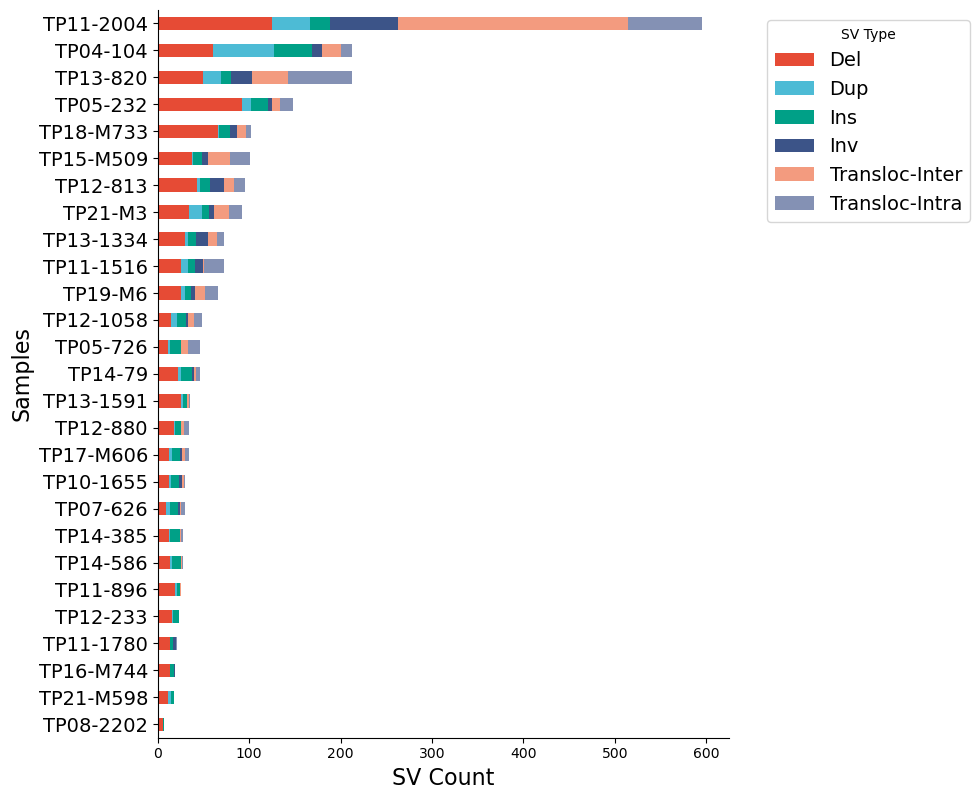

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# =============================
# CONFIG
# =============================
file_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/SV_df_unqiue.csv"
sample_col = "sample"
type_col = "Type"

# === COLOR MAP FOR SV TYPES ===
type_colors = {
    "Del": "#E64B35",
    "Dup": "#4DBBD5",
    "Ins": "#00A087",
    "Inv": "#3C5488",
    "Transloc-Inter": "#F39B7F",
    "Transloc-Intra": "#8491B4",
}

# =============================
# LOAD AND CLEAN
# =============================
df = pd.read_csv(file_path, low_memory=False)
df.columns = [col.strip().replace('\r', '') for col in df.columns]
df = df[[sample_col, type_col]].dropna()
df[type_col] = df[type_col].str.strip()
df = df[df[type_col].isin(type_colors.keys())]

# =============================
# SPLIT PDO vs TUMOR
# =============================
pdo_df = df[df[sample_col].str.startswith("IPM")].copy()
tumor_df = df[df[sample_col].str.startswith("TP")].copy()

# =============================
# FUNCTION TO COMPUTE STATS + PLOT
# =============================
def plot_sv_count_barplot(data, title, output_file):
    if data.empty:
        print(f"No data found for {title}")
        return

    # Count SVs by sample and type
    sv_counts = data.groupby([sample_col, type_col]).size().reset_index(name="Count")

    # Pivot for stacked bar layout
    sv_pivot = sv_counts.pivot(index=sample_col, columns=type_col, values="Count").fillna(0)
    sv_pivot["Total"] = sv_pivot.sum(axis=1)

    # ===== Print summary stats =====
    print(f"\n=== {title} SV Summary ===")
    print(f"Total samples: {len(sv_pivot)}")
    print(f"Max SVs per sample: {sv_pivot['Total'].max():,}")
    print(f"Mean SVs per sample: {sv_pivot['Total'].mean():.2f}")
    print(f"Min SVs per sample: {sv_pivot['Total'].min():,}")
    print(f"Total SVs (all samples): {int(sv_pivot['Total'].sum()):,}")

    # ===== Sort samples by total count =====
    sv_pivot = sv_pivot.sort_values("Total", ascending=True)
    sv_pivot_no_total = sv_pivot.drop(columns="Total")

    # ===== Plot =====
    sv_pivot_no_total.plot(
        kind="barh",
        stacked=True,
        figsize=(10, max(6, len(sv_pivot_no_total) * 0.3)),
        color=[type_colors[t] for t in sv_pivot_no_total.columns]
    )

    # plt.title(f"{title}: SV Count per Sample", fontsize=16, fontweight="bold")
    plt.xlabel("SV Count", fontsize=16)
    plt.ylabel("Samples", fontsize=16)
    plt.yticks(fontsize=14)
    plt.legend(title="SV Type", bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=14)

    # ✅ X-axis tick interval every 100
    plt.xticks(range(0, int(sv_pivot["Total"].max()) + 100, 100))

    # ✅ Remove top and right spines
    sns.despine(top=True, right=True)

    plt.tight_layout()
    plt.savefig(output_file, dpi=300)
    plt.show()


# =============================
# RUN FOR PDO AND TUMOR
# =============================
plot_sv_count_barplot(
    pdo_df,
    "PDO Samples",
    "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/SV_Count_perSample_PDO.png"
)

plot_sv_count_barplot(
    tumor_df,
    "Tumor Samples",
    "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/SV_Count_perSample_Tumor.png"
)


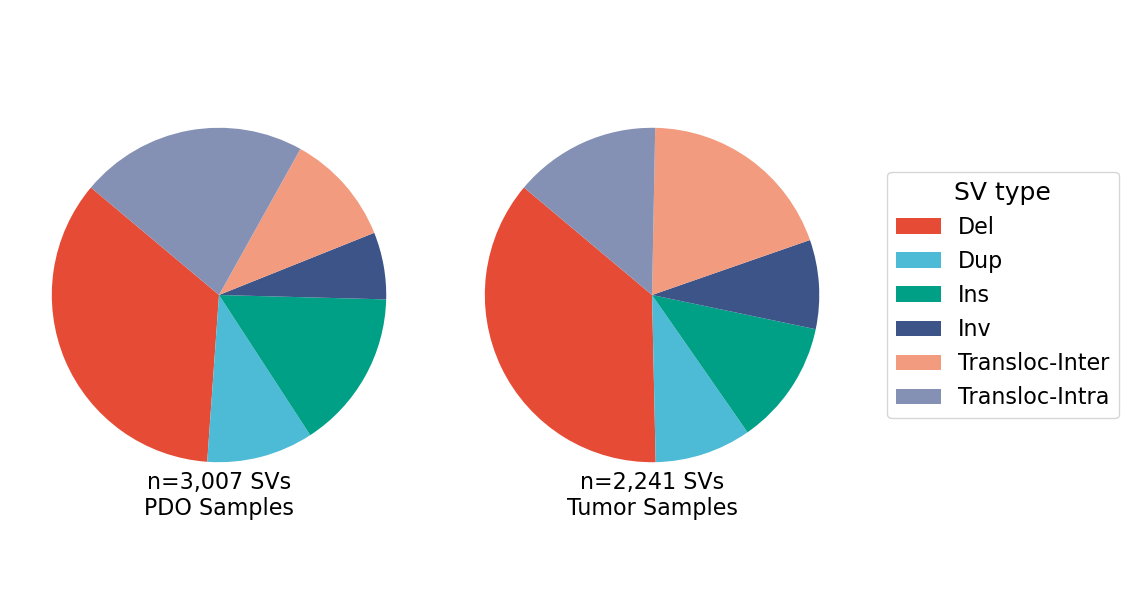

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# === CONFIG ===
file_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/SV_df_unqiue.csv"
sample_col = "sample"
type_col = "Type"

# === COLOR MAP FOR SV TYPES ===
type_colors = {
    "Del": "#E64B35",
    "Dup": "#4DBBD5",
    "Ins": "#00A087",
    "Inv": "#3C5488",
    "Transloc-Inter": "#F39B7F",
    "Transloc-Intra": "#8491B4",
}

# === LOAD DATA ===
df = pd.read_csv(file_path, low_memory=False)
df.columns = [col.strip().replace('\r', '') for col in df.columns]
df = df[[sample_col, type_col]].dropna()
df[type_col] = df[type_col].astype(str).str.strip()

# Filter only defined types
df = df[df[type_col].isin(type_colors.keys())]

# === SPLIT INTO PDO AND TUMOR ===
pdo_df = df[df[sample_col].str.startswith("IPM")].copy()
tumor_df = df[df[sample_col].str.startswith("TP")].copy()

# === PLOTTING FUNCTION ===
def plot_type_piecharts(pdo_df, tumor_df, output_file):
    pdo_counts = pdo_df[type_col].value_counts().reindex(type_colors.keys(), fill_value=0)
    tumor_counts = tumor_df[type_col].value_counts().reindex(type_colors.keys(), fill_value=0)

    fig, axes = plt.subplots(1, 3, figsize=(12, 6), gridspec_kw={'width_ratios': [1, 1, 0.6]})

    # --- PDO pie ---
    axes[0].pie(
        pdo_counts,
        labels=None,
        colors=[type_colors[k] for k in pdo_counts.index],
        startangle=140
    )
    axes[0].text(0, -1.2, f"n={pdo_counts.sum():,} SVs\nPDO Samples", 
                 ha='center', va='center', fontsize=16)

    # --- Tumor pie ---
    axes[1].pie(
        tumor_counts,
        labels=None,
        colors=[type_colors[k] for k in tumor_counts.index],
        startangle=140
    )
    axes[1].text(0, -1.2, f"n={tumor_counts.sum():,} SVs\nTumor Samples", 
                 ha='center', va='center', fontsize=16)

    # --- Legend ---
    legend_handles = [Patch(facecolor=type_colors[t], label=t) for t in type_colors]
    axes[2].legend(
        handles=legend_handles,
        loc='center left',
        fontsize=16,
        title="SV type",
        title_fontsize=18
    )
    axes[2].axis('off')

    plt.tight_layout()
    plt.savefig(output_file, dpi=300)
    plt.show()

# === RUN THE PLOT ===
plot_type_piecharts(
    pdo_df,
    tumor_df,
    "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/SV_type_distribution_PDO_vs_Tumor.png"
)


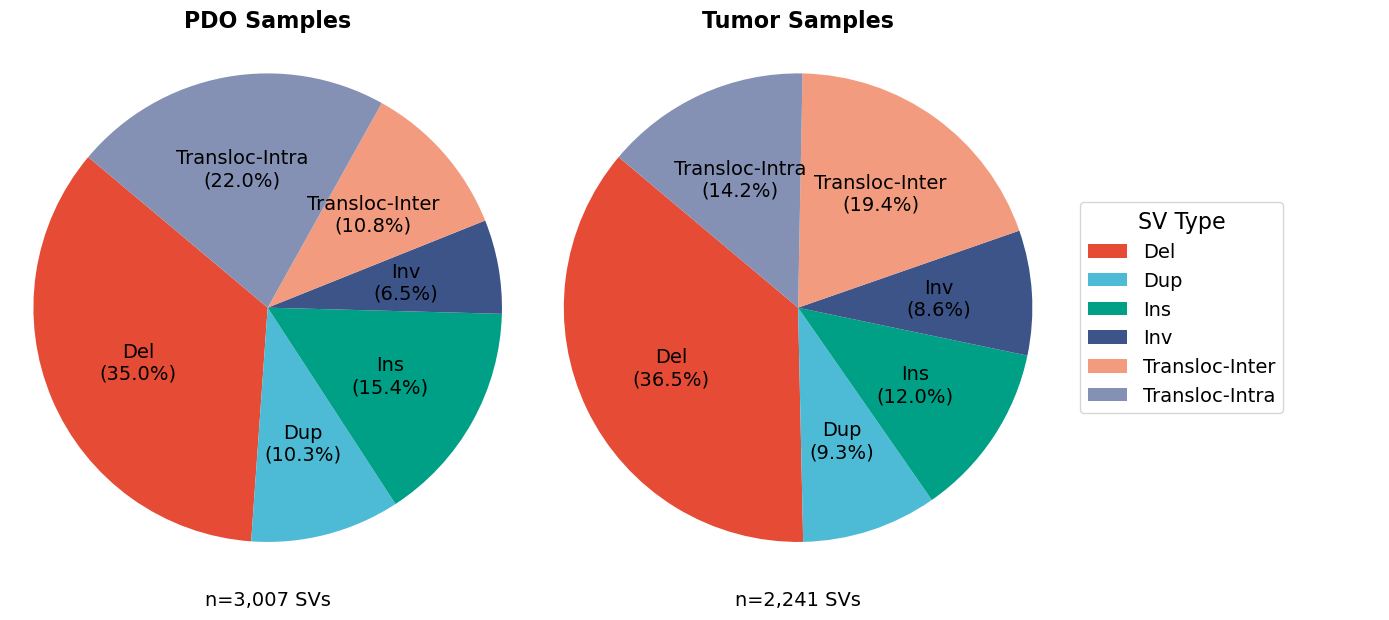

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# === CONFIG ===
file_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/SV_df_unqiue.csv"
sample_col = "sample"
type_col = "Type"

# === COLOR MAP FOR SV TYPES ===
type_colors = {
    "Del": "#E64B35",
    "Dup": "#4DBBD5",
    "Ins": "#00A087",
    "Inv": "#3C5488",
    "Transloc-Inter": "#F39B7F",
    "Transloc-Intra": "#8491B4",
}

# === LOAD DATA ===
df = pd.read_csv(file_path, low_memory=False)
df.columns = [col.strip().replace('\r', '') for col in df.columns]
df = df[[sample_col, type_col]].dropna()
df[type_col] = df[type_col].astype(str).str.strip()
df = df[df[type_col].isin(type_colors.keys())]

# === SPLIT INTO PDO AND TUMOR ===
pdo_df = df[df[sample_col].str.startswith("IPM")].copy()
tumor_df = df[df[sample_col].str.startswith("TP")].copy()


# === FUNCTION: GENERIC PIE ===
def make_pie(ax, data_counts, title):
    total = data_counts.sum()
    wedges, texts = ax.pie(
        data_counts,
        labels=None,
        colors=[type_colors[k] for k in data_counts.index],
        startangle=140
    )

    # Add inside labels manually with type and percentage
    for w, (t, v) in zip(wedges, data_counts.items()):
        ang = (w.theta2 + w.theta1) / 2
        x = 0.6 * plt.np.cos(plt.np.deg2rad(ang))
        y = 0.6 * plt.np.sin(plt.np.deg2rad(ang))
        pct = v / total * 100 if total > 0 else 0
        ax.text(
            x, y,
            f"{type_display.get(t, t)}\n({pct:.1f}%)",
            ha='center', va='center',
            fontsize=14, color='black'
        )

    ax.set_title(title, fontsize=16, fontweight='bold')
    ax.text(0, -1.25, f"n={total:,} SVs", ha='center', va='center', fontsize=14)
    ax.axis('equal')
    return ax


# === FUNCTION: MAIN PLOT ===
def plot_type_piecharts(pdo_df, tumor_df, output_prefix):
    import numpy as np
    plt.np = np  # attach numpy to plt for internal function use

    pdo_counts = pdo_df[type_col].value_counts().reindex(type_colors.keys(), fill_value=0)
    tumor_counts = tumor_df[type_col].value_counts().reindex(type_colors.keys(), fill_value=0)

    # --- COMBINED FIGURE ---
    fig, axes = plt.subplots(1, 3, figsize=(14, 6), gridspec_kw={'width_ratios': [1, 1, 0.6]})
    make_pie(axes[0], pdo_counts, "PDO Samples")
    make_pie(axes[1], tumor_counts, "Tumor Samples")

    # --- LEGEND PANEL ---
    legend_handles = [Patch(facecolor=type_colors[t], label=t) for t in type_colors]
    axes[2].legend(
        handles=legend_handles,
        loc='center left',
        fontsize=14,
        title="SV Type",
        title_fontsize=16
    )
    axes[2].axis('off')

    plt.tight_layout()
    plt.savefig(f"{output_prefix}_combined.png", dpi=300)
    plt.show()
    plt.close(fig)

    # --- SAVE COMPONENTS SEPARATELY ---
    # PDO only
    fig_pdo, ax_pdo = plt.subplots(figsize=(5, 5))
    make_pie(ax_pdo, pdo_counts, "PDO Samples")
    plt.tight_layout()
    plt.savefig(f"{output_prefix}_PDO_only.png", dpi=300)
    plt.close(fig_pdo)

    # Tumor only
    fig_tumor, ax_tumor = plt.subplots(figsize=(5, 5))
    make_pie(ax_tumor, tumor_counts, "Tumor Samples")
    plt.tight_layout()
    plt.savefig(f"{output_prefix}_Tumor_only.png", dpi=300)
    plt.close(fig_tumor)

    # Legend only
    fig_leg, ax_leg = plt.subplots(figsize=(3, 4))
    ax_leg.axis('off')
    ax_leg.legend(
        handles=legend_handles,
        loc='center',
        fontsize=14,
        title="SV Type",
        title_fontsize=16
    )
    plt.tight_layout()
    plt.savefig(f"{output_prefix}_Legend_only.png", dpi=300)
    plt.close(fig_leg)


# === RUN ===
plot_type_piecharts(
    pdo_df,
    tumor_df,
    "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/SV_type_distribution"
)


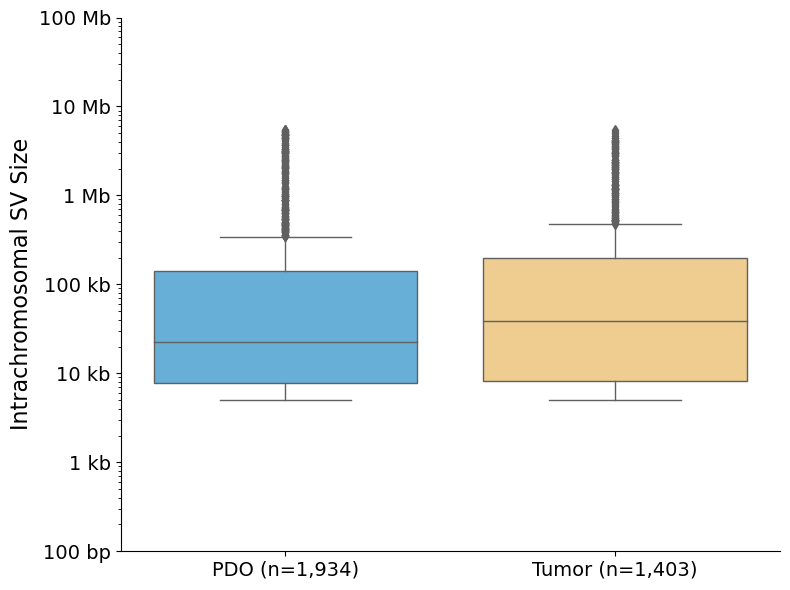

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# === CONFIG ===
file_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/SV_df_unqiue.csv"
sample_col = "sample"
ref1_col = "RefcontigID1"
ref2_col = "RefcontigID2"
size_col = "SVsize"

# === LOAD AND CLEAN DATA ===
df = pd.read_csv(file_path, low_memory=False)
df.columns = [col.strip().replace('\r', '') for col in df.columns]

# === FILTER INTRACHROMOSOMAL SVs ===
df = df[df[ref1_col] == df[ref2_col]]
df = df[[sample_col, size_col]].dropna()
df[size_col] = pd.to_numeric(df[size_col], errors='coerce')
df = df[df[size_col] > 0]

# === LABEL GROUPS ===
df['Group'] = df[sample_col].apply(
    lambda s: 'PDO' if str(s).startswith("IPM") else 'Tumor' if str(s).startswith("TP") else None
)
df = df[df['Group'].notna()]

# === COUNT PER GROUP ===
group_counts = df['Group'].value_counts()
pdo_label = f"PDO (n={group_counts.get('PDO', 0):,})"
tumor_label = f"Tumor (n={group_counts.get('Tumor', 0):,})"

# === PLOT ===
plt.figure(figsize=(8, 6))
sns.boxplot(
    data=df,
    x='Group',
    y=size_col,
    palette=["#56B4E9", "#FFD180"],  # Blue for PDO, Peachy-pale orange for Tumor
    linewidth=1
)


plt.yscale('log')
plt.yticks(
    ticks=[1e2, 1e3, 1e4, 1e5, 1e6, 1e7, 1e8],
    labels=["100 bp", "1 kb", "10 kb", "100 kb", "1 Mb", "10 Mb", "100 Mb"],
    fontsize=14
)
plt.ylabel("Intrachromosomal SV Size", fontsize=16)
plt.xlabel("")
plt.xticks([0, 1], [pdo_label, tumor_label], fontsize=14)

# === Remove box and extra axes ===
sns.despine(top=True, right=True)

plt.tight_layout()
plt.savefig("/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/SV_df_intrachromosomal_SV_size_boxplot.png", dpi=300)
plt.show()


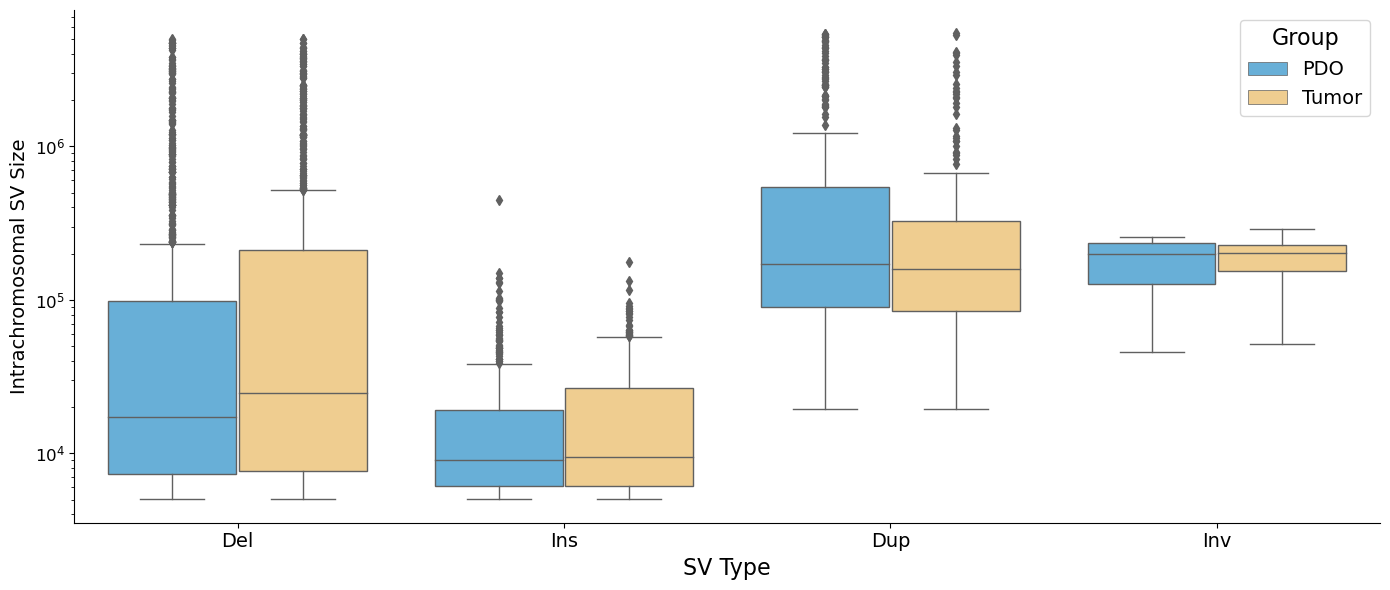

  SV Type  PDO n  Tumor n  U Statistic   p-value
0     Del   1052      817     393215.5  0.001599
2     Dup    310      209      35572.0  0.057991
1     Ins    463      270      60346.5  0.435151
3     Inv    109      107       5863.0  0.946182


In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# === CONFIG ===
file_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/SV_df_unqiue.csv"
sample_col = "sample"
ref1_col = "RefcontigID1"
ref2_col = "RefcontigID2"
size_col = "SVsize"
sv_type_col = "Type"

# === LOAD AND CLEAN DATA ===
df = pd.read_csv(file_path, low_memory=False)
df.columns = [col.strip().replace('\r', '') for col in df.columns]

# === BASIC CLEANING ===
df = df[
    (df[ref1_col] == df[ref2_col])  # Intrachromosomal only
][[sample_col, size_col, ref1_col, ref2_col, sv_type_col]].dropna()

df[size_col] = pd.to_numeric(df[size_col], errors='coerce')
df = df[df[size_col] > 0]

# === LABEL GROUPS ===
df['Group'] = df[sample_col].apply(
    lambda s: 'PDO' if str(s).startswith("IPM") else 'Tumor' if str(s).startswith("TP") else None
)
df = df[df['Group'].notna()]

# === 1. SV Type Breakdown Bar Plot ===
# plt.figure(figsize=(10, 5))
# type_counts = df[sv_type_col].value_counts()
# sns.barplot(x=type_counts.index, y=type_counts.values)
# plt.ylabel("Count")
# plt.title("SV Type Distribution (Intrachromosomal)")
# plt.xticks(rotation=45)
# plt.tight_layout()
# plt.savefig("intrachr_sv_type_barplot.png", dpi=300)
# plt.show()

# === 2. SV Size Distribution by SV Type (Violin Plot) ===
# plt.figure(figsize=(12, 6))
# sns.violinplot(data=df, x=sv_type_col, y=size_col, scale='width', inner='quartile')
# plt.yscale('log')
# plt.ylabel("SV Size (log scale)")
# plt.title("Intrachromosomal SV Sizes by Type")
#plt.xticks(rotation=45)
# plt.tight_layout()
# plt.savefig("intrachr_sv_size_by_type_violin.png", dpi=300)
#plt.show()

# === 3. SV Size by Type and Group (Boxplot) ===
plt.figure(figsize=(14, 6))
sns.boxplot(
    data=df,
    x=sv_type_col,
    y=size_col,
    hue='Group',
    palette=["#56B4E9", "#FFD180"],  # Blue for PDO, Peachy-orange for Tumor
    linewidth=1
)

plt.yscale('log')
plt.ylabel("Intrachromosomal SV Size", fontsize=14)
plt.xlabel("SV Type", fontsize=16)
plt.xticks(rotation=0, fontsize=14)
plt.yticks(fontsize=12)
plt.legend(title='Group', fontsize=14, title_fontsize=16)
sns.despine(top=True, right=True) # Remove top and right axes
plt.tight_layout()
plt.savefig("/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/intrachr_sv_size_by_type_and_group_boxplot.png", dpi=300)
plt.show()

from scipy.stats import mannwhitneyu
import pandas as pd

results = []

# Loop through each SV type
for sv_type in df[sv_type_col].dropna().unique():
    subset = df[df[sv_type_col] == sv_type]
    pdo_sizes = subset[subset['Group'] == 'PDO'][size_col].dropna()
    tumor_sizes = subset[subset['Group'] == 'Tumor'][size_col].dropna()
    
    # Proceed only if both groups have data
    if len(pdo_sizes) > 0 and len(tumor_sizes) > 0:
        stat, p = mannwhitneyu(pdo_sizes, tumor_sizes, alternative='two-sided')
        results.append((sv_type, len(pdo_sizes), len(tumor_sizes), stat, p))

# Convert to DataFrame and display
results_df = pd.DataFrame(results, columns=["SV Type", "PDO n", "Tumor n", "U Statistic", "p-value"])
results_df.sort_values("p-value", inplace=True)
print(results_df)


In [10]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# === CONFIG ===
file_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/SV_df_unqiue.csv"
sample_col = "sample"
ref1_col = "RefcontigID1"
ref2_col = "RefcontigID2"
ref_start_col = "RefStartPos"
ref_end_col = "RefEndPos"
size_col = "SVsize"
sv_type_col = "Type"

# === LOAD AND CLEAN ===
df = pd.read_csv(file_path, low_memory=False)
df.columns = [col.strip().replace('\r', '') for col in df.columns]

# === FILTER INTRACHROMOSOMAL SVs ===
df = df[df[ref1_col] == df[ref2_col]]
df = df[[sample_col, sv_type_col, size_col, ref_start_col, ref_end_col]].dropna()

# === ASSIGN GROUPS ===
df['Group'] = df[sample_col].apply(
    lambda s: 'PDO' if str(s).startswith("IPM") else 'Tumor' if str(s).startswith("TP") else None
)
df = df[df['Group'].notna()]

# === VALIDATION STEP ===

def validate_intrachr_sv_data(df, sample_col="sample", sv_type_col="Type",
                               size_col="SVsize", ref_start_col="RefStartPos", ref_end_col="RefEndPos"):
    report = {}

    # Count of SVs by Group and Type
    sv_count_table = df.groupby(['Group', sv_type_col]).size().unstack(fill_value=0)
    report['sv_count_table'] = sv_count_table

    # SV Size Summary
    df[size_col] = pd.to_numeric(df[size_col], errors='coerce')
    sv_size_summary = df.groupby(['Group', sv_type_col])[size_col].describe()
    report['sv_size_summary'] = sv_size_summary

    # Check for invalid SV sizes
    invalid_svsize_count = df[df[size_col] <= 0].shape[0]
    report['invalid_svsize_count'] = invalid_svsize_count

    # SVsize vs |RefEndPos - RefStartPos|
    df[ref_start_col] = pd.to_numeric(df[ref_start_col], errors='coerce')
    df[ref_end_col] = pd.to_numeric(df[ref_end_col], errors='coerce')
    df['SVsize_check'] = (df[ref_end_col] - df[ref_start_col]).abs()
    df['size_mismatch'] = ~np.isclose(df[size_col], df['SVsize_check'], atol=1)

    mismatch_df = df[df['size_mismatch']][[size_col, 'SVsize_check', sv_type_col, 'Group']]
    report['mismatch_sample_rows'] = mismatch_df.head()

    return report

# Run validation
report = validate_intrachr_sv_data(df)

# === PRINT REPORT ===
print("\n=== SV Count Table ===")
print(report['sv_count_table'])

print("\n=== SV Size Summary ===")
print(report['sv_size_summary'])

print(f"\n=== Invalid SVsize Count: {report['invalid_svsize_count']} ===")

print("\n=== SVsize Mismatch Sample Rows ===")
print(report['mismatch_sample_rows'])



=== SV Count Table ===
Type    Del  Dup  Ins  Inv  Transloc-Intra
Group                                     
PDO    1052  310  463  109             661
Tumor   817  209  270  107             318

=== SV Size Summary ===
                       count           mean           std      min        25%  \
Group Type                                                                      
PDO   Del             1052.0  267179.027567  7.515027e+05   5012.0    7278.25   
      Dup              310.0  766794.458065  1.292700e+06  19381.0   90054.50   
      Ins              463.0   18443.103672  2.937187e+04   5007.0    6119.50   
      Inv              109.0  176821.302752  6.365122e+04  45982.0  126444.00   
      Transloc-Intra   661.0      -1.000000  0.000000e+00     -1.0      -1.00   
Tumor Del              817.0  378603.162791  8.657245e+05   5010.0    7673.00   
      Dup              209.0  475753.334928  8.991093e+05  19369.0   84964.00   
      Ins              270.0   20672.992593  2.421

In [39]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# === CONFIG ===
file_path = "/bgfs/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/SV_df_unqiue.csv"
sample_col = "sample"
ref1_col = "RefcontigID1"
ref2_col = "RefcontigID2"
size_col = "Size"

# === LOAD AND CLEAN ===
df = pd.read_csv(file_path, low_memory=False)
df.columns = [col.strip().replace('\r', '') for col in df.columns]

# === FILTER INTERCHROMOSOMAL SVs ===
df = df[df[ref1_col] != df[ref2_col]]  # Interchromosomal only
df = df[[sample_col, size_col]].dropna()
df[size_col] = pd.to_numeric(df[size_col], errors='coerce')
df = df[df[size_col] > 0]

# === Proceed only if SVs exist ===
if df.empty:
    print("⚠️ No interchromosomal SVs found in the dataset.")
else:
    # Label and plot (same as before)
    df['Group'] = df[sample_col].apply(
        lambda s: 'PDO' if str(s).startswith("IPM") else 'Tumor' if str(s).startswith("TP") else None
    )
    df = df[df['Group'].notna()]

    group_counts = df['Group'].value_counts()
    pdo_label = f"PDO (n={group_counts.get('PDO', 0):,})"
    tumor_label = f"Tumor (n={group_counts.get('Tumor', 0):,})"

    plt.figure(figsize=(8, 6))
    sns.boxplot(
        data=df,
        x='Group',
        y=size_col,
        palette=["#56B4E9", "#E69F00"],
        linewidth=1
    )

    plt.yscale('log')
    plt.ylabel("Interchromosomal SV Size", fontsize=14)
    plt.xlabel("")
    plt.xticks([0, 1], [pdo_label, tumor_label], fontsize=12)
    sns.despine(top=True, right=True)
    plt.tight_layout()
    plt.savefig("/bgfs/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/interchromosomal_SV_size_boxplot.png", dpi=300)
    plt.show()



⚠️ No interchromosomal SVs found in the dataset.


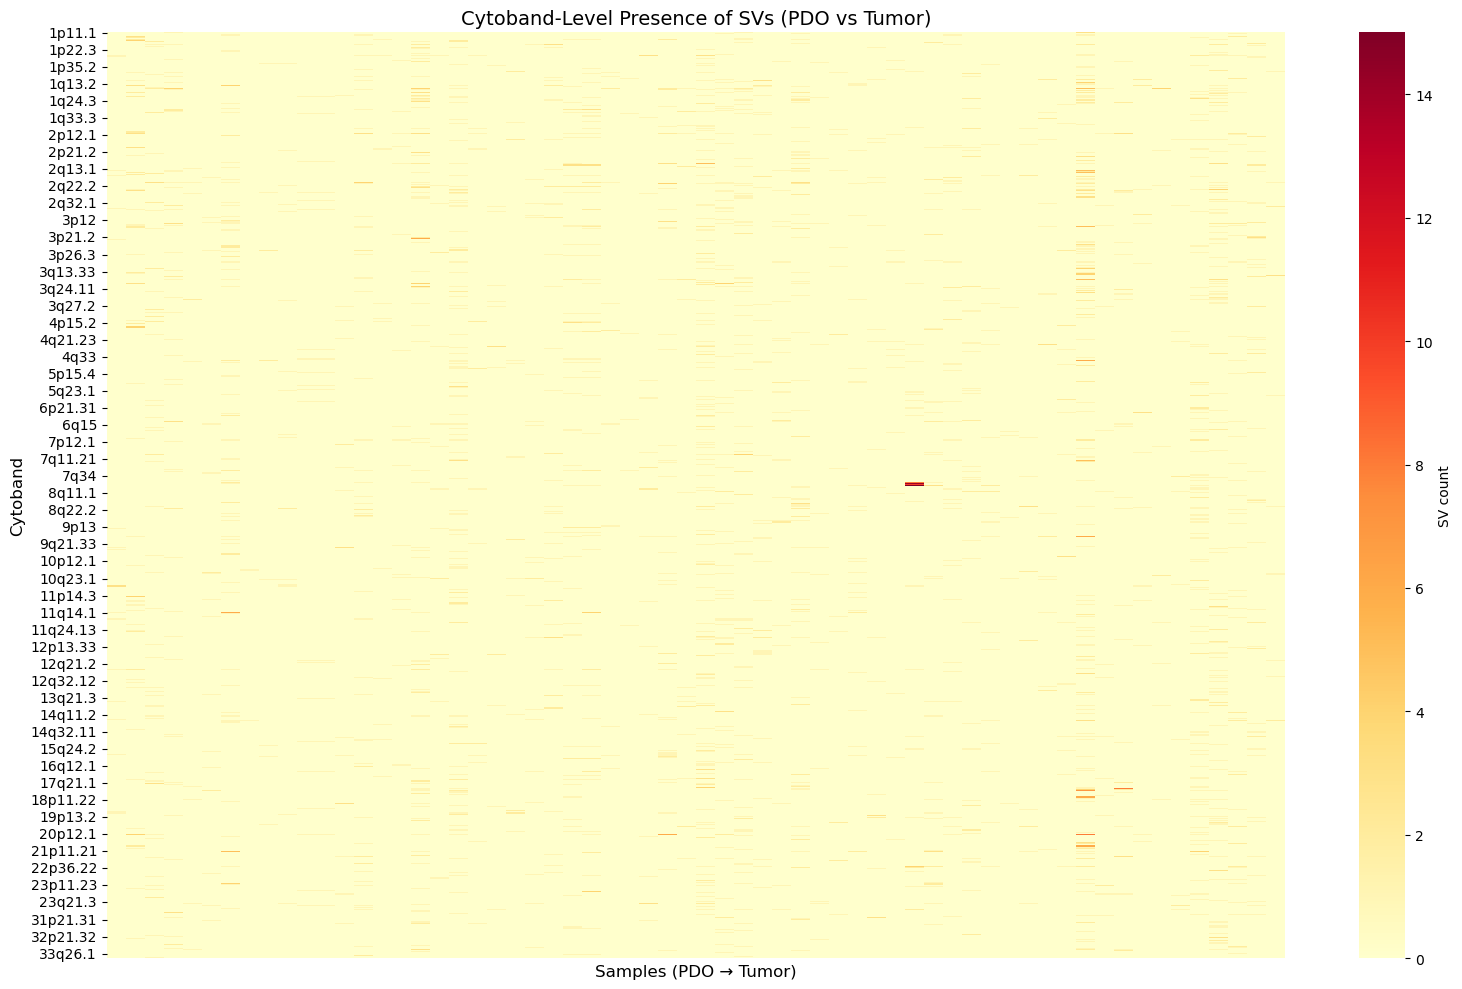

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re

# === CONFIG ===
file_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/SV_df_unqiue.csv"
sample_col = "sample"
iscn_col = "ISCN_sample"

# === LOAD & CLEAN DATA ===
df = pd.read_csv(file_path, low_memory=False)
df.columns = [col.strip().replace('\r', '') for col in df.columns]
df = df[[sample_col, iscn_col]].dropna()

# === EXTRACT CYTOBANDS FROM ISCN_sample ===
def extract_cytobands(text):
    return re.findall(r'\b\d+[pq]\d+(?:\.\d+)?\b', text)

# Expand into multiple rows per sample–cytoband pair
expanded = []
for _, row in df.iterrows():
    sample = row[sample_col]
    cytobands = extract_cytobands(row[iscn_col])
    for cb in cytobands:
        expanded.append({'sample': sample, 'cytoband': cb})

df_expanded = pd.DataFrame(expanded)

# === GROUP BY PDO vs TUMOR ===
df_expanded['Group'] = df_expanded['sample'].apply(
    lambda s: 'PDO' if str(s).startswith("IPM") else 'Tumor' if str(s).startswith("TP") else 'Other'
)
df_expanded = df_expanded[df_expanded['Group'] != 'Other']

# === CREATE PRESENCE MATRIX: Cytoband × Sample ===
presence_matrix = df_expanded.pivot_table(
    index='cytoband',
    columns='sample',
    aggfunc='size',
    fill_value=0
)

# === SORT SAMPLES BY GROUP ===
sample_group = df_expanded.drop_duplicates('sample')[['sample', 'Group']].set_index('sample')
sample_order = sample_group.sort_values('Group').index.tolist()
presence_matrix = presence_matrix[sample_order]

# === SORT CYTOBANDS BY CHROMOSOMAL ORDER ===
def sort_cytobands(c):
    match = re.match(r'(\d+|X|Y)([pq])(\d+(?:\.\d+)?)', c)
    if match:
        chr_val = int(match.group(1)) if match.group(1).isdigit() else (23 if match.group(1) == 'X' else 24)
        arm = 0 if match.group(2) == 'p' else 1
        band = float(match.group(3))
        return (chr_val, arm, band)
    return (999, 0, 0)  # push unknown to bottom

presence_matrix = presence_matrix.sort_index(key=lambda x: x.map(sort_cytobands))

# === PLOT ===
plt.figure(figsize=(16, 10))
sns.heatmap(
    presence_matrix,
    cmap='YlOrRd',
    cbar_kws={'label': 'SV count'},
    xticklabels=False  # optional: hide x labels if too many samples
)
plt.ylabel("Cytoband", fontsize=12)
plt.xlabel("Samples (PDO → Tumor)", fontsize=12)
plt.title("Cytoband-Level Presence of SVs (PDO vs Tumor)", fontsize=14)
plt.tight_layout()

# === SAVE FIGURE ===
plt.savefig("/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/cytoband_SV_heatmap.png", dpi=300)
plt.show()


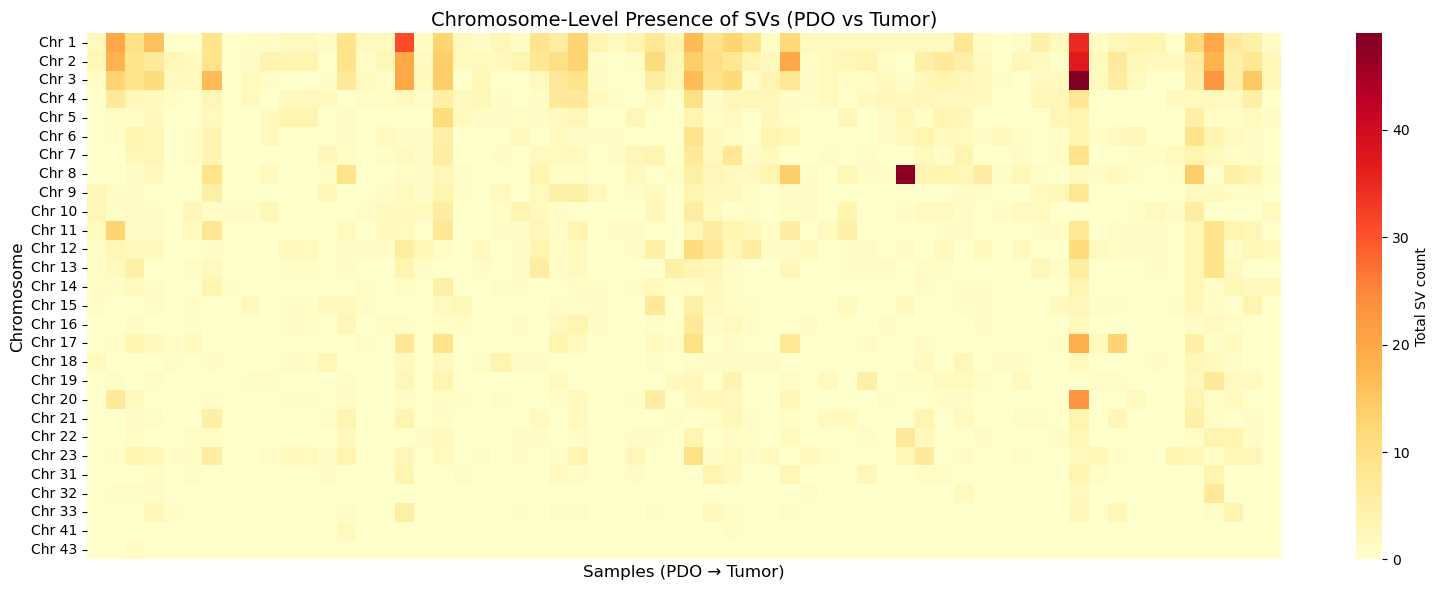

In [7]:
# === MAP CYTOBAND → CHROMOSOME ===
df_expanded['chromosome'] = df_expanded['cytoband'].apply(
    lambda cb: re.match(r'(\d+|X|Y)', cb).group(1) if re.match(r'(\d+|X|Y)', cb) else None
)

df_expanded = df_expanded[df_expanded['chromosome'].notnull()]

# === GROUP BY CHROMOSOME × SAMPLE AND COUNT ===
chromosome_matrix = df_expanded.groupby(['chromosome', 'sample']).size().unstack(fill_value=0)

# Sort chromosomes naturally: 1–22, X, Y
def chr_sort_key(c):
    return int(c) if c.isdigit() else (23 if c == 'X' else 24)

chromosome_matrix = chromosome_matrix.loc[sorted(chromosome_matrix.index, key=chr_sort_key)]

# Reorder columns to match sample order (PDO → Tumor)
chromosome_matrix = chromosome_matrix[sample_order]

# === PLOT AGGREGATED HEATMAP ===
plt.figure(figsize=(16, 6))
ax = sns.heatmap(
    chromosome_matrix,
    cmap='YlOrRd',
    cbar_kws={'label': 'Total SV count'},
    xticklabels=False,
    yticklabels=['Chr ' + str(c) for c in chromosome_matrix.index]
)

ax.set_ylabel("Chromosome", fontsize=12)
ax.set_xlabel("Samples (PDO → Tumor)", fontsize=12)
ax.set_title("Chromosome-Level Presence of SVs (PDO vs Tumor)", fontsize=14)
plt.tight_layout()

# === SAVE & SHOW ===
plt.savefig("/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/chromosome_SV_heatmap.png", dpi=300)
plt.show()


Plotting 42 enriched cytobands (≥ 10 total SVs)


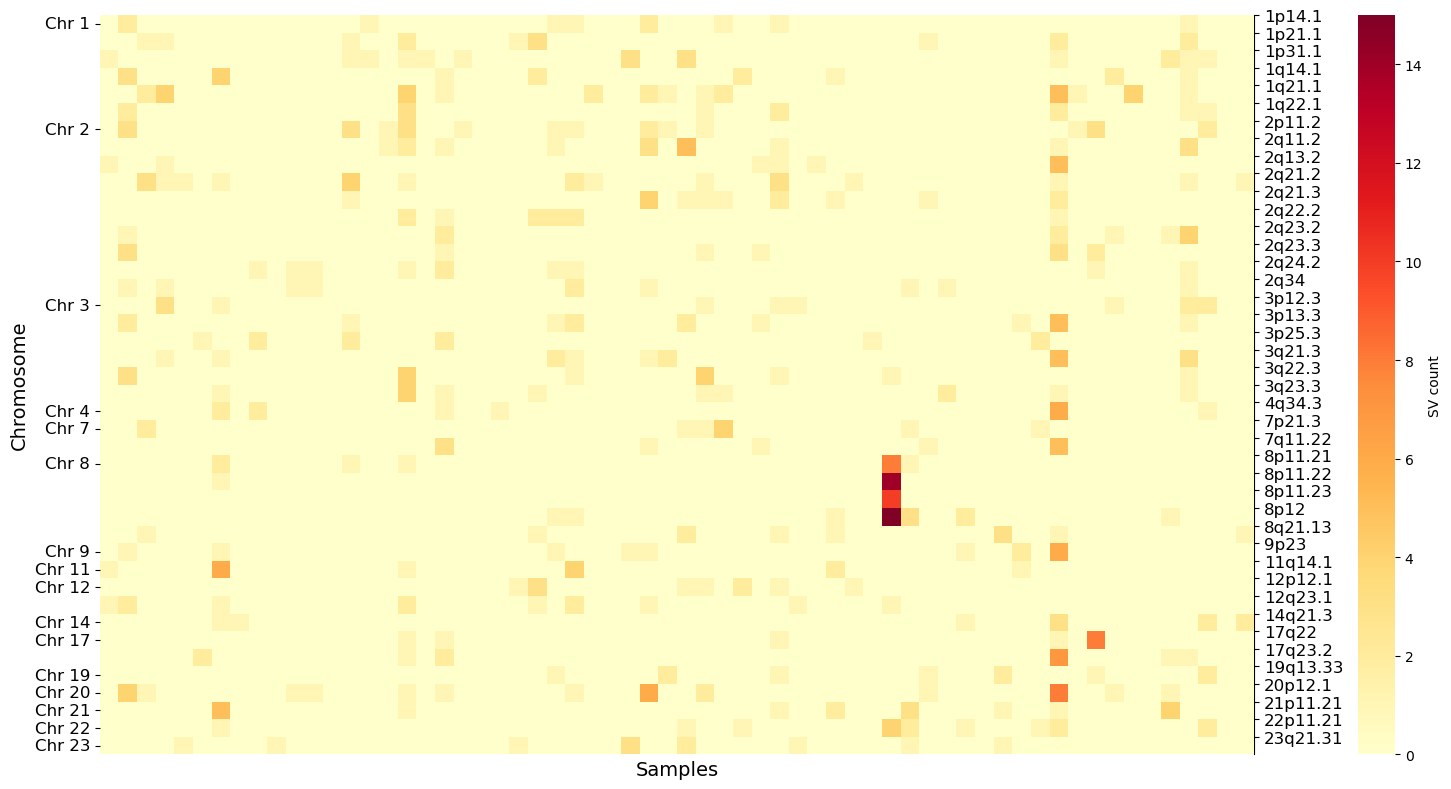

In [8]:
# === FILTER: KEEP ONLY ENRICHED CYTOBANDS ===
min_total_sv = 10
presence_matrix_filtered = presence_matrix[presence_matrix.sum(axis=1) >= min_total_sv]

print(f"Plotting {presence_matrix_filtered.shape[0]} enriched cytobands (≥ {min_total_sv} total SVs)")

# === Prepare chromosome labels for LEFT Y-axis ===
cytobands = presence_matrix_filtered.index.tolist()
chrom_labels = [
    'Chr ' + re.match(r'(\d+|X|Y)', cb).group(1) if re.match(r'(\d+|X|Y)', cb) else ''
    for cb in cytobands
]

# === PLOT FILTERED HEATMAP ===
plt.figure(figsize=(16,8))
ax = sns.heatmap(
    presence_matrix_filtered,
    cmap='YlOrRd',
    cbar_kws={'label': 'SV count', 'pad': 0.07},
    xticklabels=False,
    yticklabels=True
)

# Left Y-axis: Chromosome labels
# Generate clustered chromosome labels (only show once per group)
clustered_labels = []
prev_chr = None
for chrom in chrom_labels:
    if chrom != prev_chr:
        clustered_labels.append(chrom)
        prev_chr = chrom
    else:
        clustered_labels.append('')  # skip duplicates
# Apply clustered labels and suppress tick marks for blanks
ax.set_yticklabels(clustered_labels, fontsize=12)
for tick, label in zip(ax.yaxis.get_major_ticks(), clustered_labels):
    if label == '':
        tick.tick1line.set_visible(False)
        tick.tick2line.set_visible(False)
ax.set_ylabel("Chromosome", fontsize=14)

# Right Y-axis: Full cytoband names
ax_right = ax.secondary_yaxis('right')
ax_right.set_yticks(range(len(cytobands)))
ax_right.set_yticklabels(cytobands, fontsize=12)
# ax_right.set_ylabel("Cytoband", fontsize=12)

# Final styling
ax.set_xlabel("Samples", fontsize=14)
plt.tight_layout()

plt.savefig("/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/enriched_cytobands_heatmap.png", dpi=300)
plt.show()


Plotting 42 enriched cytobands (≥ 10 total SVs)
Top 10 Cytobands by SV Count:
 cytoband
1q21.1      30
20p12.1     29
8p12        24
2p11.2      23
2q21.2      22
21p11.21    18
2q11.2      18
1p31.1      17
1q14.1      16
3p13.3      16
dtype: int64


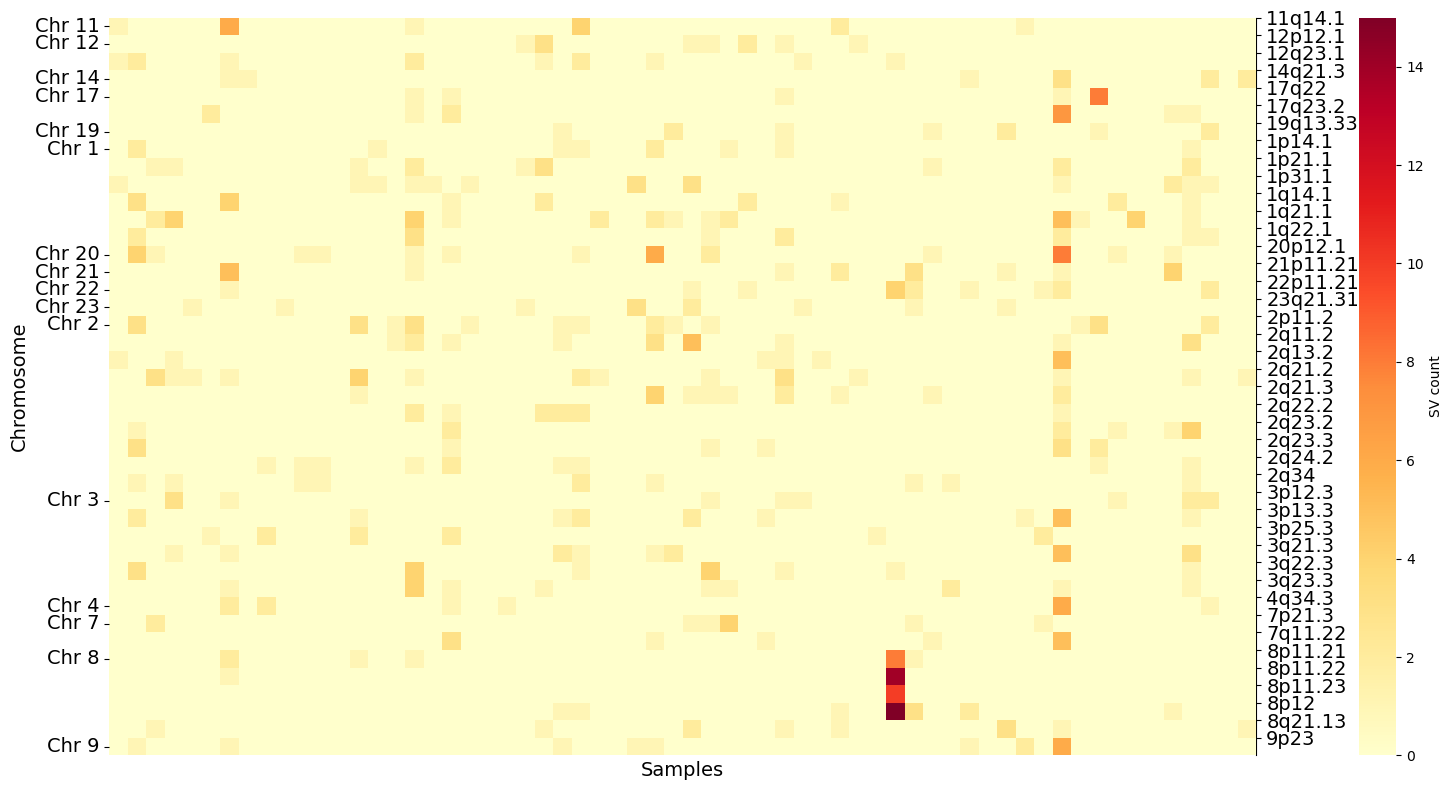

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re

# === CONFIG ===
file_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/SV_df_unqiue.csv"
sample_col = "sample"
iscn_col = "ISCN_sample"

# === LOAD & CLEAN DATA ===
df = pd.read_csv(file_path, low_memory=False)
df.columns = [col.strip().replace('\r', '') for col in df.columns]
df = df[[sample_col, iscn_col]].dropna()

# === EXTRACT CYTOBANDS FROM ISCN_sample ===
def extract_cytobands(text):
    return re.findall(r'\b\d+[pq]\d+(?:\.\d+)?\b', text)

# Expand into multiple rows per sample cytoband pair
expanded = []
for _, row in df.iterrows():
    sample = row[sample_col]
    cytobands = extract_cytobands(row[iscn_col])
    for cb in cytobands:
        expanded.append({'sample': sample, 'cytoband': cb})

df_expanded = pd.DataFrame(expanded)

# === GROUP BY PDO vs TUMOR ===
df_expanded['Group'] = df_expanded['sample'].apply(
    lambda s: 'PDO' if str(s).startswith("IPM") else 'Tumor' if str(s).startswith("TP") else 'Other'
)
df_expanded = df_expanded[df_expanded['Group'] != 'Other']

# === CREATE PRESENCE MATRIX: Cytoband Ã— Sample ===
presence_matrix = df_expanded.pivot_table(
    index='cytoband',
    columns='sample',
    aggfunc='size',
    fill_value=0
)

# === SORT SAMPLES BY GROUP ===
sample_group = df_expanded.drop_duplicates('sample')[['sample', 'Group']].set_index('sample')
sample_order = sample_group.sort_values('Group').index.tolist()
presence_matrix = presence_matrix[sample_order]

# === FILTER: KEEP ONLY ENRICHED CYTOBANDS ===
min_total_sv = 10
presence_matrix_filtered = presence_matrix[presence_matrix.sum(axis=1) >= min_total_sv]

print(f"Plotting {presence_matrix_filtered.shape[0]} enriched cytobands (≥ {min_total_sv} total SVs)")

# === Prepare chromosome labels for LEFT Y-axis ===
cytobands = presence_matrix_filtered.index.tolist()
chrom_labels = [
    'Chr ' + re.match(r'(\d+|X|Y)', cb).group(1) if re.match(r'(\d+|X|Y)', cb) else ''
    for cb in cytobands
]

print("Top 10 Cytobands by SV Count:\n", presence_matrix_filtered.sum(axis=1).nlargest(10))

# === PLOT FILTERED HEATMAP ===
plt.figure(figsize=(16,8))
ax = sns.heatmap(
    presence_matrix_filtered,
    cmap='YlOrRd',
    cbar_kws={'label': 'SV count', 'pad': 0.07},
    xticklabels=False,
    yticklabels=True
)

# Left Y-axis: Chromosome labels
# Generate clustered chromosome labels (only show once per group)
clustered_labels = []
prev_chr = None
for chrom in chrom_labels:
    if chrom != prev_chr:
        clustered_labels.append(chrom)
        prev_chr = chrom
    else:
        clustered_labels.append('')  # skip duplicates
# Apply clustered labels and suppress tick marks for blanks
ax.set_yticklabels(clustered_labels, fontsize=14)
for tick, label in zip(ax.yaxis.get_major_ticks(), clustered_labels):
    if label == '':
        tick.tick1line.set_visible(False)
        tick.tick2line.set_visible(False)
ax.set_ylabel("Chromosome", fontsize=14)

# Right Y-axis: Full cytoband names
ax_right = ax.secondary_yaxis('right')
ax_right.set_yticks(range(len(cytobands)))
ax_right.set_yticklabels(cytobands, fontsize=14)
# ax_right.set_ylabel("Cytoband", fontsize=12)

# Final styling
ax.set_xlabel("Samples", fontsize=14)
plt.tight_layout()

plt.savefig("/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/enriched_cytobands_heatmap.png", dpi=300)
plt.show()


Top 10 Cytobands by SV Count:
 cytoband
1q21.1      30
20p12.1     29
8p12        24
2p11.2      23
2q21.2      22
21p11.21    18
2q11.2      18
1p31.1      17
1q14.1      16
3p13.3      16
dtype: int64


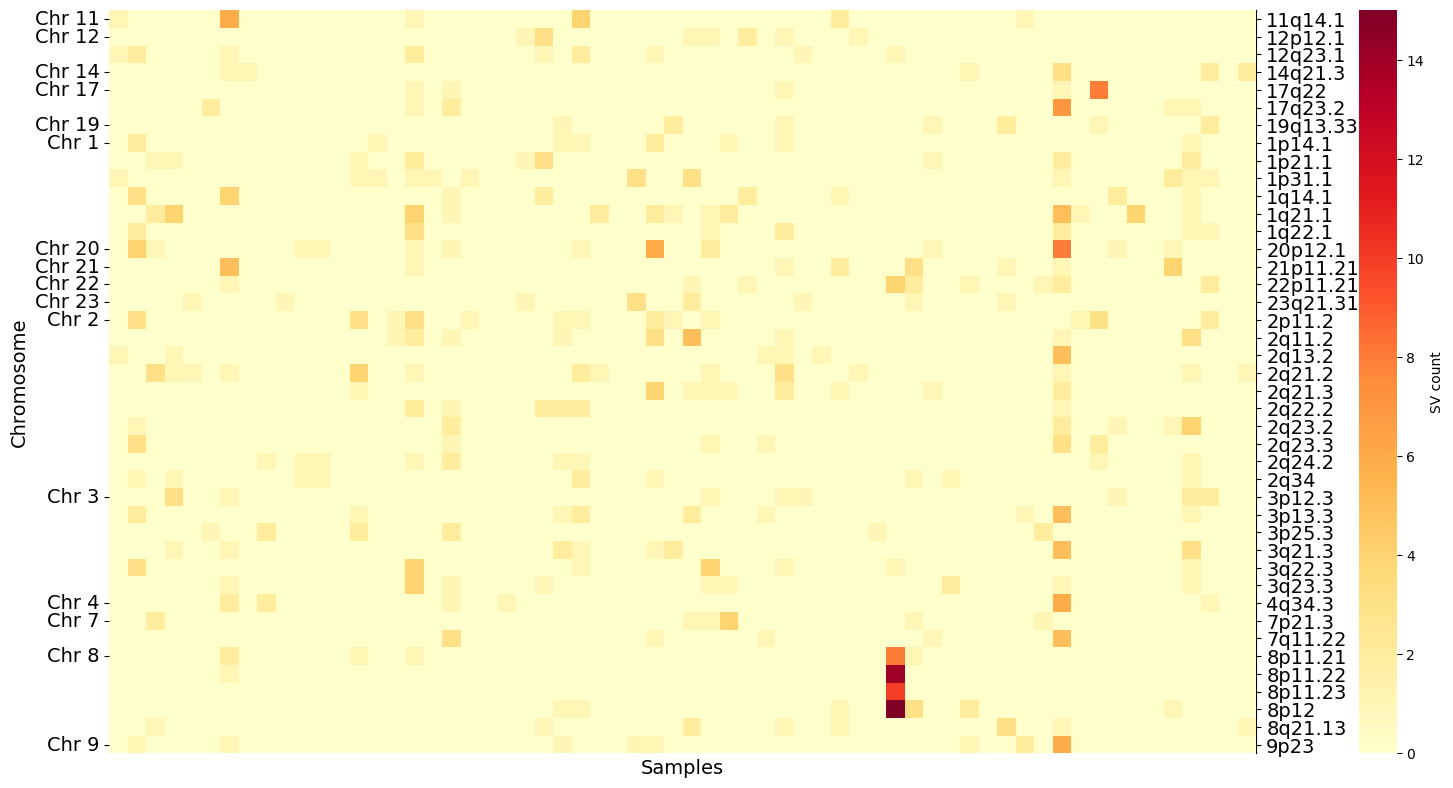

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re

# === CONFIG ===
file_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/SV_df_unqiue.csv"
sample_col = "sample"
iscn_col = "ISCN_sample"

# === LOAD & CLEAN DATA ===
df = pd.read_csv(file_path, low_memory=False)
df.columns = [col.strip().replace('\r', '') for col in df.columns]
df = df[[sample_col, iscn_col]].dropna()

# === EXTRACT CYTOBANDS FROM ISCN_sample ===
def extract_cytobands(text):
    return re.findall(r'\b\d+[pq]\d+(?:\.\d+)?\b', text)

# Expand into multiple rows per sample cytoband pair
expanded = []
for _, row in df.iterrows():
    sample = row[sample_col]
    cytobands = extract_cytobands(row[iscn_col])
    for cb in cytobands:
        expanded.append({'sample': sample, 'cytoband': cb})

df_expanded = pd.DataFrame(expanded)

# === GROUP BY PDO vs TUMOR ===
df_expanded['Group'] = df_expanded['sample'].apply(
    lambda s: 'PDO' if str(s).startswith("IPM") else 'Tumor' if str(s).startswith("TP") else 'Other'
)
df_expanded = df_expanded[df_expanded['Group'] != 'Other']

# === CREATE PRESENCE MATRIX: Cytoband × Sample ===
presence_matrix = df_expanded.pivot_table(
    index='cytoband',
    columns='sample',
    aggfunc='size',
    fill_value=0
)

# === SORT SAMPLES BY GROUP ===
sample_group = df_expanded.drop_duplicates('sample')[['sample', 'Group']].set_index('sample')
sample_order = sample_group.sort_values('Group').index.tolist()
presence_matrix = presence_matrix[sample_order]

# === FILTER: KEEP ONLY ENRICHED CYTOBANDS ===
min_total_sv = 10
presence_matrix_filtered = presence_matrix[presence_matrix.sum(axis=1) >= min_total_sv]

# === Prepare chromosome labels for LEFT Y-axis ===
cytobands = presence_matrix_filtered.index.tolist()
chrom_labels = [
    'Chr ' + re.match(r'(\d+|X|Y)', cb).group(1) if re.match(r'(\d+|X|Y)', cb) else ''
    for cb in cytobands
]
print("Top 10 Cytobands by SV Count:\n", presence_matrix_filtered.sum(axis=1).nlargest(10))
# === PLOT FILTERED HEATMAP ===
plt.figure(figsize=(16,8))
ax = sns.heatmap(
    presence_matrix_filtered,
    cmap='YlOrRd',
    cbar_kws={'label': 'SV count', 'pad': 0.07},
    xticklabels=False,
    yticklabels=True
)

# Left Y-axis: Chromosome labels
clustered_labels = []
prev_chr = None
for chrom in chrom_labels:
    if chrom != prev_chr:
        clustered_labels.append(chrom)
        prev_chr = chrom
    else:
        clustered_labels.append('')  # skip duplicates

ax.set_yticklabels(clustered_labels, fontsize=14)
for tick, label in zip(ax.yaxis.get_major_ticks(), clustered_labels):
    if label == '':
        tick.tick1line.set_visible(False)
        tick.tick2line.set_visible(False)
ax.set_ylabel("Chromosome", fontsize=14)

# Right Y-axis: Full cytoband names, centered in the cell
ax_right = ax.secondary_yaxis('right')
centered_positions = [tick + 0.5 for tick in range(len(cytobands))]
ax_right.set_yticks(centered_positions)
ax_right.set_yticklabels(cytobands, fontsize=14)

# Final styling
ax.set_xlabel("Samples", fontsize=14)
plt.tight_layout()

plt.savefig("/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/enriched_cytobands_heatmap.png", dpi=300)
plt.show()


Top 10 Cytobands by SV Count:
 cytoband
1q21.1      30
20p12.1     29
8p12        24
2p11.2      23
2q21.2      22
2q11.2      18
21p11.21    18
1p31.1      17
1q14.1      16
3p13.3      16
dtype: int64


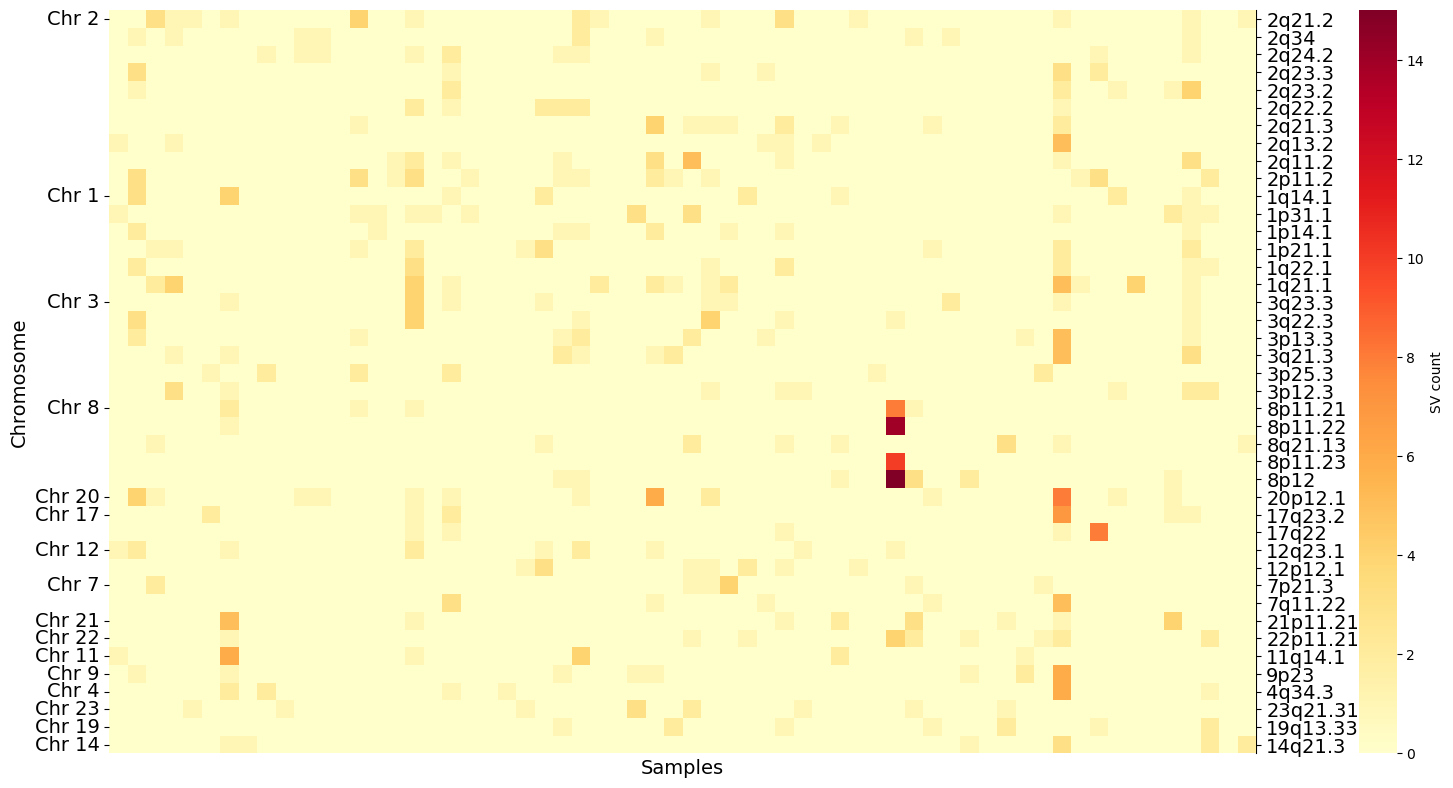

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re

# === CONFIG ===
file_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/SV_df_unqiue.csv"
sample_col = "sample"
iscn_col = "ISCN_sample"

# === LOAD & CLEAN DATA ===
df = pd.read_csv(file_path, low_memory=False)
df.columns = [col.strip().replace('\r', '') for col in df.columns]
df = df[[sample_col, iscn_col]].dropna()

# === EXTRACT CYTOBANDS FROM ISCN_sample ===
def extract_cytobands(text):
    return re.findall(r'\b\d+[pq]\d+(?:\.\d+)?\b', text)

# Expand into multiple rows per sample cytoband pair
expanded = []
for _, row in df.iterrows():
    sample = row[sample_col]
    cytobands = extract_cytobands(row[iscn_col])
    for cb in cytobands:
        expanded.append({'sample': sample, 'cytoband': cb})

df_expanded = pd.DataFrame(expanded)

# === GROUP BY PDO vs TUMOR ===
df_expanded['Group'] = df_expanded['sample'].apply(
    lambda s: 'PDO' if str(s).startswith("IPM") else 'Tumor' if str(s).startswith("TP") else 'Other'
)
df_expanded = df_expanded[df_expanded['Group'] != 'Other']

# === CREATE PRESENCE MATRIX: Cytoband × Sample ===
presence_matrix = df_expanded.pivot_table(
    index='cytoband',
    columns='sample',
    aggfunc='size',
    fill_value=0
)

# === SORT SAMPLES BY GROUP ===
sample_group = df_expanded.drop_duplicates('sample')[['sample', 'Group']].set_index('sample')
sample_order = sample_group.sort_values('Group').index.tolist()
presence_matrix = presence_matrix[sample_order]

# === FILTER: KEEP ONLY ENRICHED CYTOBANDS ===
min_total_sv = 10
presence_matrix_filtered = presence_matrix[presence_matrix.sum(axis=1) >= min_total_sv].copy()

# === STEP 1: Extract chromosome from cytoband
presence_matrix_filtered['chrom'] = presence_matrix_filtered.index.str.extract(r'^(\d+|X|Y)', expand=False)

# === STEP 2: Compute total SVs per chromosome
chr_sv_counts = (
    presence_matrix_filtered.drop(columns='chrom')
    .groupby(presence_matrix_filtered['chrom'])
    .sum()
    .sum(axis=1)
    .sort_values(ascending=False)
)

# === STEP 3: Sort cytobands by chromosome SV totals
ordered_chroms = chr_sv_counts.index.tolist()
presence_matrix_filtered['chrom'] = pd.Categorical(presence_matrix_filtered['chrom'], categories=ordered_chroms, ordered=True)
presence_matrix_filtered.sort_values(['chrom'], inplace=True)

# === STEP 4: Prepare labels and drop temp column
cytobands = presence_matrix_filtered.index.tolist()
chrom_labels = presence_matrix_filtered['chrom'].astype(str).tolist()
presence_matrix_filtered = presence_matrix_filtered.drop(columns='chrom')

print("Top 10 Cytobands by SV Count:\n", presence_matrix_filtered.sum(axis=1).nlargest(10))

# === PLOT FILTERED HEATMAP ===
plt.figure(figsize=(16, 8))
ax = sns.heatmap(
    presence_matrix_filtered,
    cmap='YlOrRd',
    cbar_kws={'label': 'SV count', 'pad': 0.07},
    xticklabels=False,
    yticklabels=True
)

# Left Y-axis: Sorted chromosome labels (no duplicates)
clustered_labels = []
prev_chr = None
for chrom in chrom_labels:
    if chrom != prev_chr:
        clustered_labels.append("Chr " + chrom)
        prev_chr = chrom
    else:
        clustered_labels.append('')

ax.set_yticklabels(clustered_labels, fontsize=14)
for tick, label in zip(ax.yaxis.get_major_ticks(), clustered_labels):
    if label == '':
        tick.tick1line.set_visible(False)
        tick.tick2line.set_visible(False)

ax.set_ylabel("Chromosome", fontsize=14)

# Right Y-axis: Full cytoband names, centered
ax_right = ax.secondary_yaxis('right')
centered_positions = [tick + 0.5 for tick in range(len(cytobands))]
ax_right.set_yticks(centered_positions)
ax_right.set_yticklabels(cytobands, fontsize=14)

# Final styling
ax.set_xlabel("Samples", fontsize=14)
plt.tight_layout()
plt.savefig("/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/enriched_cytobands_heatmap.png", dpi=300)
plt.show()


Top 10 Cytobands by SV Count:
 cytoband
8p12        22
8p11.22     14
21p11.21    12
22p11.21    12
20p12.1     11
1q21.1      11
8p11.23     10
17q22       10
dtype: int64


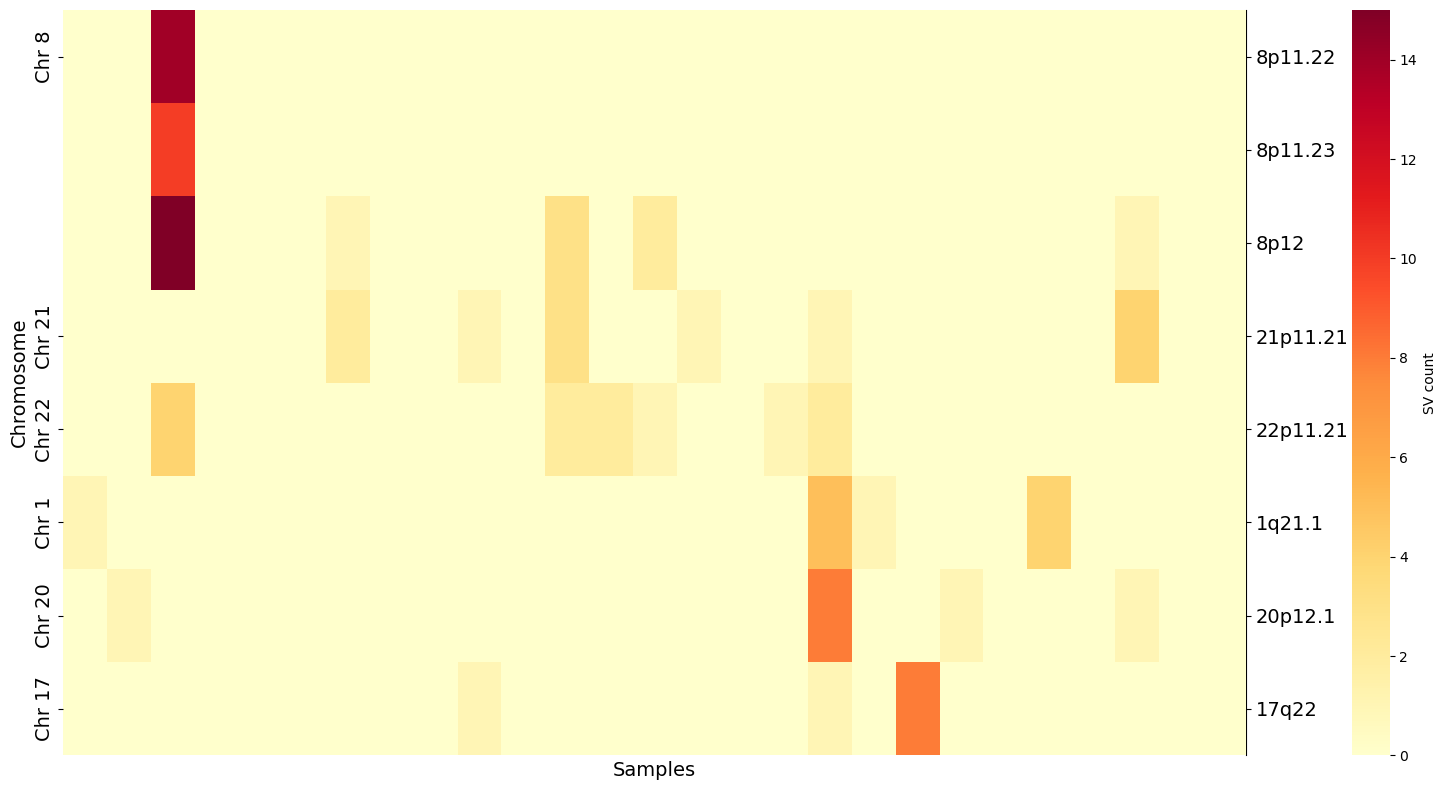

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re

# === CONFIG ===
file_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/SV_df_unqiue_Tumor.csv"
sample_col = "sample"
iscn_col = "ISCN_sample"

# === LOAD & CLEAN DATA ===
df = pd.read_csv(file_path, low_memory=False)
df.columns = [col.strip().replace('\r', '') for col in df.columns]
df = df[[sample_col, iscn_col]].dropna()

# === EXTRACT CYTOBANDS FROM ISCN_sample ===
def extract_cytobands(text):
    return re.findall(r'\b\d+[pq]\d+(?:\.\d+)?\b', text)

# Expand into multiple rows per sample cytoband pair
expanded = []
for _, row in df.iterrows():
    sample = row[sample_col]
    cytobands = extract_cytobands(row[iscn_col])
    for cb in cytobands:
        expanded.append({'sample': sample, 'cytoband': cb})

df_expanded = pd.DataFrame(expanded)

# === GROUP BY PDO vs TUMOR ===
df_expanded['Group'] = df_expanded['sample'].apply(
    lambda s: 'PDO' if str(s).startswith("IPM") else 'Tumor' if str(s).startswith("TP") else 'Other'
)
df_expanded = df_expanded[df_expanded['Group'] != 'Other']

# === CREATE PRESENCE MATRIX: Cytoband × Sample ===
presence_matrix = df_expanded.pivot_table(
    index='cytoband',
    columns='sample',
    aggfunc='size',
    fill_value=0
)

# === SORT SAMPLES BY GROUP ===
sample_group = df_expanded.drop_duplicates('sample')[['sample', 'Group']].set_index('sample')
sample_order = sample_group.sort_values('Group').index.tolist()
presence_matrix = presence_matrix[sample_order]

# === FILTER: KEEP ONLY ENRICHED CYTOBANDS ===
min_total_sv = 10
presence_matrix_filtered = presence_matrix[presence_matrix.sum(axis=1) >= min_total_sv].copy()

# === STEP 1: Extract chromosome from cytoband
presence_matrix_filtered['chrom'] = presence_matrix_filtered.index.str.extract(r'^(\d+|X|Y)', expand=False)

# === STEP 2: Compute total SVs per chromosome
chr_sv_counts = (
    presence_matrix_filtered.drop(columns='chrom')
    .groupby(presence_matrix_filtered['chrom'])
    .sum()
    .sum(axis=1)
    .sort_values(ascending=False)
)

# === STEP 3: Sort cytobands by chromosome SV totals
ordered_chroms = chr_sv_counts.index.tolist()
presence_matrix_filtered['chrom'] = pd.Categorical(presence_matrix_filtered['chrom'], categories=ordered_chroms, ordered=True)
presence_matrix_filtered.sort_values(['chrom'], inplace=True)

# === STEP 4: Prepare labels and drop temp column
cytobands = presence_matrix_filtered.index.tolist()
chrom_labels = presence_matrix_filtered['chrom'].astype(str).tolist()
presence_matrix_filtered = presence_matrix_filtered.drop(columns='chrom')

print("Top 10 Cytobands by SV Count:\n", presence_matrix_filtered.sum(axis=1).nlargest(10))

# === PLOT FILTERED HEATMAP ===
plt.figure(figsize=(16, 8))
ax = sns.heatmap(
    presence_matrix_filtered,
    cmap='YlOrRd',
    cbar_kws={'label': 'SV count', 'pad': 0.07},
    xticklabels=False,
    yticklabels=True
)

# Left Y-axis: Sorted chromosome labels (no duplicates)
clustered_labels = []
prev_chr = None
for chrom in chrom_labels:
    if chrom != prev_chr:
        clustered_labels.append("Chr " + chrom)
        prev_chr = chrom
    else:
        clustered_labels.append('')

ax.set_yticklabels(clustered_labels, fontsize=14)
for tick, label in zip(ax.yaxis.get_major_ticks(), clustered_labels):
    if label == '':
        tick.tick1line.set_visible(False)
        tick.tick2line.set_visible(False)

ax.set_ylabel("Chromosome", fontsize=14)

# Right Y-axis: Full cytoband names, centered
ax_right = ax.secondary_yaxis('right')
centered_positions = [tick + 0.5 for tick in range(len(cytobands))]
ax_right.set_yticks(centered_positions)
ax_right.set_yticklabels(cytobands, fontsize=14)

# Final styling
ax.set_xlabel("Samples", fontsize=14)
plt.tight_layout()
plt.savefig("/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/Tumor_enriched_cytobands_heatmap.png", dpi=300)
plt.show()


Top 10 Cytobands by SV Count:
 cytoband
1q21.1     19
20p12.1    18
2p11.2     17
2q21.2     15
2q11.2     13
1p31.1     12
1q14.1     12
11q14.1    12
3q22.3     12
12q23.1    10
dtype: int64


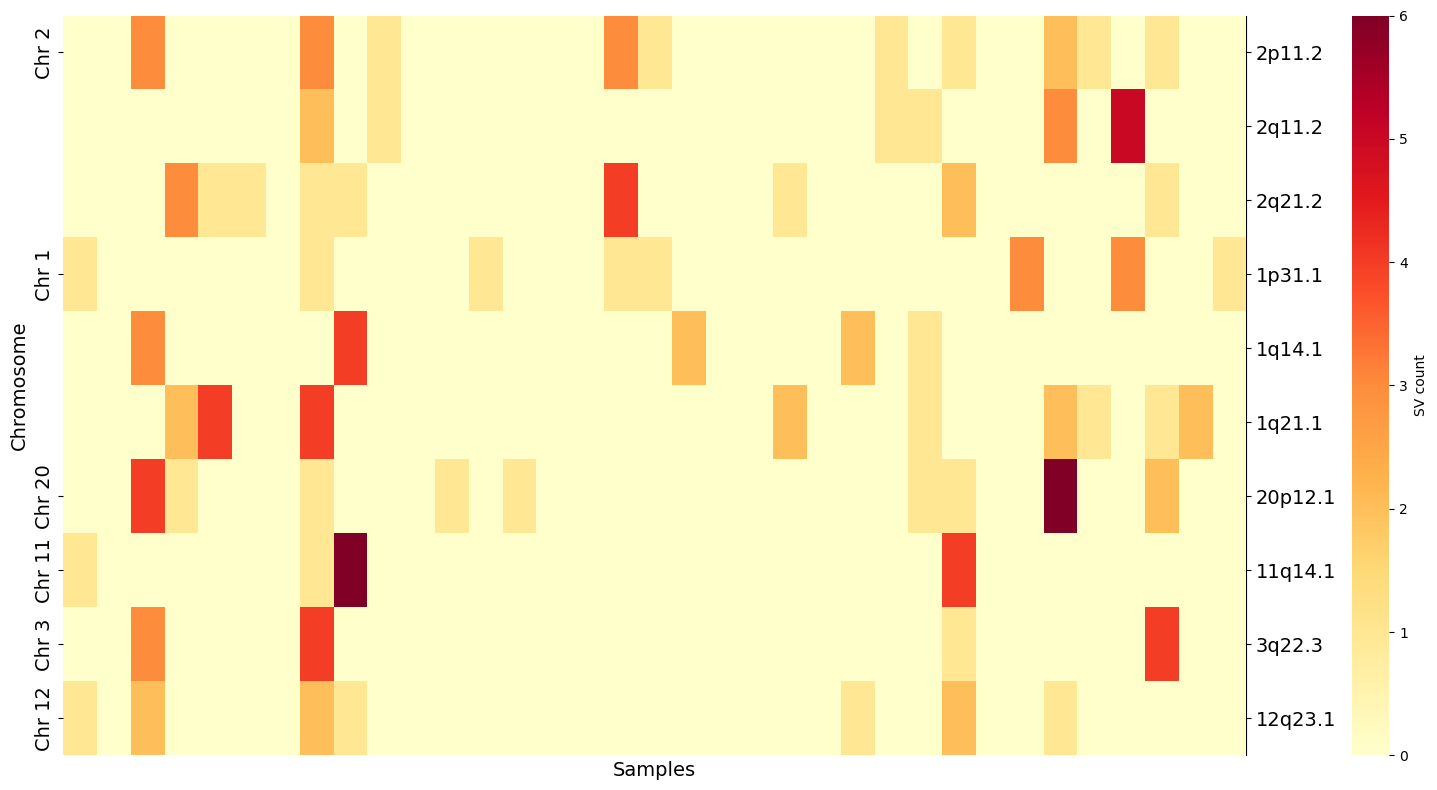

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re

# === CONFIG ===
file_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/SV_df_unqiue_IPM.csv"
sample_col = "sample"
iscn_col = "ISCN_sample"

# === LOAD & CLEAN DATA ===
df = pd.read_csv(file_path, low_memory=False)
df.columns = [col.strip().replace('\r', '') for col in df.columns]
df = df[[sample_col, iscn_col]].dropna()

# === EXTRACT CYTOBANDS FROM ISCN_sample ===
def extract_cytobands(text):
    return re.findall(r'\b\d+[pq]\d+(?:\.\d+)?\b', text)

# Expand into multiple rows per sample cytoband pair
expanded = []
for _, row in df.iterrows():
    sample = row[sample_col]
    cytobands = extract_cytobands(row[iscn_col])
    for cb in cytobands:
        expanded.append({'sample': sample, 'cytoband': cb})

df_expanded = pd.DataFrame(expanded)

# === GROUP BY PDO vs TUMOR ===
df_expanded['Group'] = df_expanded['sample'].apply(
    lambda s: 'PDO' if str(s).startswith("IPM") else 'Tumor' if str(s).startswith("TP") else 'Other'
)
df_expanded = df_expanded[df_expanded['Group'] != 'Other']

# === CREATE PRESENCE MATRIX: Cytoband × Sample ===
presence_matrix = df_expanded.pivot_table(
    index='cytoband',
    columns='sample',
    aggfunc='size',
    fill_value=0
)

# === SORT SAMPLES BY GROUP ===
sample_group = df_expanded.drop_duplicates('sample')[['sample', 'Group']].set_index('sample')
sample_order = sample_group.sort_values('Group').index.tolist()
presence_matrix = presence_matrix[sample_order]

# === FILTER: KEEP ONLY ENRICHED CYTOBANDS ===
min_total_sv = 10
presence_matrix_filtered = presence_matrix[presence_matrix.sum(axis=1) >= min_total_sv].copy()

# === STEP 1: Extract chromosome from cytoband
presence_matrix_filtered['chrom'] = presence_matrix_filtered.index.str.extract(r'^(\d+|X|Y)', expand=False)

# === STEP 2: Compute total SVs per chromosome
chr_sv_counts = (
    presence_matrix_filtered.drop(columns='chrom')
    .groupby(presence_matrix_filtered['chrom'])
    .sum()
    .sum(axis=1)
    .sort_values(ascending=False)
)

# === STEP 3: Sort cytobands by chromosome SV totals
ordered_chroms = chr_sv_counts.index.tolist()
presence_matrix_filtered['chrom'] = pd.Categorical(presence_matrix_filtered['chrom'], categories=ordered_chroms, ordered=True)
presence_matrix_filtered.sort_values(['chrom'], inplace=True)

# === STEP 4: Prepare labels and drop temp column
cytobands = presence_matrix_filtered.index.tolist()
chrom_labels = presence_matrix_filtered['chrom'].astype(str).tolist()
presence_matrix_filtered = presence_matrix_filtered.drop(columns='chrom')

print("Top 10 Cytobands by SV Count:\n", presence_matrix_filtered.sum(axis=1).nlargest(10))

# === PLOT FILTERED HEATMAP ===
plt.figure(figsize=(16, 8))
ax = sns.heatmap(
    presence_matrix_filtered,
    cmap='YlOrRd',
    cbar_kws={'label': 'SV count', 'pad': 0.07},
    xticklabels=False,
    yticklabels=True
)

# Left Y-axis: Sorted chromosome labels (no duplicates)
clustered_labels = []
prev_chr = None
for chrom in chrom_labels:
    if chrom != prev_chr:
        clustered_labels.append("Chr " + chrom)
        prev_chr = chrom
    else:
        clustered_labels.append('')

ax.set_yticklabels(clustered_labels, fontsize=14)
for tick, label in zip(ax.yaxis.get_major_ticks(), clustered_labels):
    if label == '':
        tick.tick1line.set_visible(False)
        tick.tick2line.set_visible(False)

ax.set_ylabel("Chromosome", fontsize=14)

# Right Y-axis: Full cytoband names, centered
ax_right = ax.secondary_yaxis('right')
centered_positions = [tick + 0.5 for tick in range(len(cytobands))]
ax_right.set_yticks(centered_positions)
ax_right.set_yticklabels(cytobands, fontsize=14)

# Final styling
ax.set_xlabel("Samples", fontsize=14)
plt.tight_layout()
plt.savefig("/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/IPM_enriched_cytobands_heatmap.png", dpi=300)
plt.show()
